# Trabajo Práctico Especial - Fundamentos de la Ciencia de Datos (2026)
## Stack Overflow Developer Survey 2025

# 1. Análisis exploratorio inicial
### 1.1. Origen y descarga de los datos

Usamos la encuesta Stack Overflow Developer Survey 2025 y su esquema de preguntas, descargados de la misma versión del repositorio oficial. La participación fue voluntaria, por lo que la muestra no representa necesariamente a todos los desarrolladores.

Fuentes: [metodología](https://survey.stackoverflow.co/2025/methodology) y [archivos originales](https://github.com/StackExchange/Survey/tree/6ae2209cd35a55e92739ba82f7887fb86807a069/packages/archive/2025).


In [1]:
from wget import download
from os import path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 20)

url_resultados = "https://media.githubusercontent.com/media/StackExchange/Survey/6ae2209cd35a55e92739ba82f7887fb86807a069/packages/archive/2025/results.csv"
url_esquema = "https://media.githubusercontent.com/media/StackExchange/Survey/6ae2209cd35a55e92739ba82f7887fb86807a069/packages/archive/2025/schema.csv"

if not path.exists("schema.csv"):
    download(url_esquema, "schema.csv", bar=None)

if not path.exists("results.csv"):
    download(url_resultados, "results.csv", bar=None)

print("Archivos de entrada: results.csv y schema.csv")


Archivos de entrada: results.csv y schema.csv


### 1.2. Lectura de los archivos y metadatos

Leemos los CSV y revisamos sus dimensiones y el esquema de preguntas.


In [2]:
metadatos = pd.read_csv("schema.csv")
datos_originales = pd.read_csv("results.csv", low_memory=False)
print("Metadatos:", metadatos.shape, "| Respuestas:", datos_originales.shape)
metadatos[["qname", "type", "sub"]].head(5)


Metadatos: (139, 6) | Respuestas: (49191, 172)


,qname,type,sub
0,TechEndorse_1,RO,AI integration or AI Agent capabilities
1,TechEndorse_2,RO,Easy-to-use API
2,TechEndorse_3,RO,Robust and complete API
3,TechEndorse_4,RO,Customizable and manageable codebase
4,TechEndorse_5,RO,Reputation for quality


El esquema tiene 139 filas y las respuestas, 49.191 filas y 172 columnas. Algunas preguntas generan varias columnas. Los tipos `MC`, `TE`, `Matrix` y `RO` corresponden a selección, entrada escrita, matriz y ranking de opciones.


In [3]:
print(metadatos["type"].value_counts().to_string())


type
RO        49
MC        48
TE        29
Matrix    13


### 1.3. Primera exploración de las respuestas

La selección parte del enunciado: país y compensación; experiencia y confianza en IA; satisfacción, prioridades y cambio laboral. En la hipótesis multivariada usamos la modalidad de trabajo (`RemoteWork`) y el tamaño de empresa (`OrgSize`). Para comparar tamaños de empresa también tenemos en cuenta el rol (`ICorPM`), la experiencia (`WorkExp`) y el sector (`Industry`).

`ResponseId` identifica respuestas y `MainBranch` distingue perfiles. `Age` permite revisar los años declarados. Para comparar compensaciones usamos `ConvertedCompYearly` (USD anuales); `CompTotal` y `Currency` muestran el monto y la moneda originales.


In [4]:
datos_originales[["ResponseId", "MainBranch", "Age", "WorkExp", "Country", "Currency", "CompTotal","ConvertedCompYearly", "AIAcc"]].head(5)


,ResponseId,MainBranch,Age,WorkExp,Country,Currency,CompTotal,ConvertedCompYearly,AIAcc
0,1,I am a developer by profession,25-34 years old,8.0,Ukraine,EUR European Euro,52800.0,61256.0,Neither trust nor distrust
1,2,I am a developer by profession,25-34 years old,2.0,Netherlands,EUR European Euro,90000.0,104413.0,Neither trust nor distrust
2,3,I am a developer by profession,35-44 years old,10.0,Ukraine,UAH Ukrainian hryvnia,2214000.0,53061.0,Somewhat trust
3,4,I am a developer by profession,35-44 years old,4.0,Ukraine,EUR European Euro,31200.0,36197.0,Somewhat trust
4,5,I am a developer by profession,35-44 years old,21.0,Ukraine,USD United States dollar,60000.0,60000.0,Neither trust nor distrust


In [5]:
print("Tipos de datos:")
print(datos_originales.dtypes.value_counts().to_string())

datos_originales[["Age", "WorkExp", "YearsCode", "Country", "ConvertedCompYearly", "OrgSize", "RemoteWork", "ICorPM", "Industry", "AIAcc", "JobSat", "NewRole"]].info()

Tipos de datos:
str        119
float64     52
int64        1
<class 'pandas.DataFrame'>
RangeIndex: 49191 entries, 0 to 49190
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  49191 non-null  str    
 1   WorkExp              42893 non-null  float64
 2   YearsCode            43042 non-null  float64
 3   Country              35437 non-null  str    
 4   ConvertedCompYearly  23947 non-null  float64
 5   OrgSize              34178 non-null  str    
 6   RemoteWork           33780 non-null  str    
 7   ICorPM               33243 non-null  str    
 8   Industry             33642 non-null  str    
 9   AIAcc                33297 non-null  str    
 10  JobSat               26670 non-null  float64
 11  NewRole              35527 non-null  str    
dtypes: float64(4), str(8)
memory usage: 4.5 MB


### 1.4. Estadísticas descriptivas básicas de las variables numéricas

Revisamos cantidad de respuestas, centro, dispersión y extremos con `describe()`.


In [6]:
datos_originales[["WorkExp", "YearsCode", "ToolCountWork", "ToolCountPersonal", "CompTotal", "ConvertedCompYearly", "JobSat"]].describe().round(2)


,WorkExp,YearsCode,ToolCountWork,ToolCountPersonal,CompTotal,ConvertedCompYearly,JobSat
count,42893.00,43042.00,27611.00,25582.00,2.486600e+04,23947.00,26670.0
mean,13.37,16.57,17.73,8.55,2.234198e+70,101761.54,7.2
std,10.80,11.79,269.81,44.66,3.523096e+72,461756.90,2.0
min,1.00,1.00,0.00,0.00,0.000000e+00,1.00,0.0
25%,5.00,8.00,4.00,3.00,5.500000e+04,38171.00,6.0
50%,10.00,14.00,6.00,5.00,1.050000e+05,75320.00,8.0
75%,20.00,24.00,10.00,7.00,2.400000e+05,120596.00,8.0
max,100.00,100.00,10000.00,1000.00,5.555556e+74,50000000.00,10.0


#### Revisión de importes extremos en `CompTotal`

Revisamos los tres mayores importes junto con su moneda y conversión.


In [7]:
extremos_comptotal = datos_originales.sort_values(["CompTotal", "ResponseId"], ascending=[False, True]).head(3)
print(extremos_comptotal[["ResponseId", "Country", "Currency", "CompTotal", "ConvertedCompYearly"]].to_string(index=False))


 ResponseId                  Country                 Currency    CompTotal  ConvertedCompYearly
       4934 United States of America USD United States dollar 5.555556e+74                  NaN
      44527                    Nepal USD United States dollar 8.000000e+23                  NaN
      35765                    India         INR Indian rupee 1.000000e+23                  NaN


Los tres importes son inverosímiles y no tienen compensación convertida: quedan fuera de las comparaciones salariales por ese faltante. Conservamos sus otras respuestas. La media global de `CompTotal` tampoco resulta comparable porque mezcla monedas distintas.


### 1.5. Distribución de las variables principales

Los histogramas muestran concentración, asimetría y extremos. Usamos intervalos de diez años para experiencia y programación, y una barra por puntuación de satisfacción. En compensación, los intervalos y el eje logarítmicos permiten incluir todo el rango; las alturas siguen indicando cantidades de respuestas.


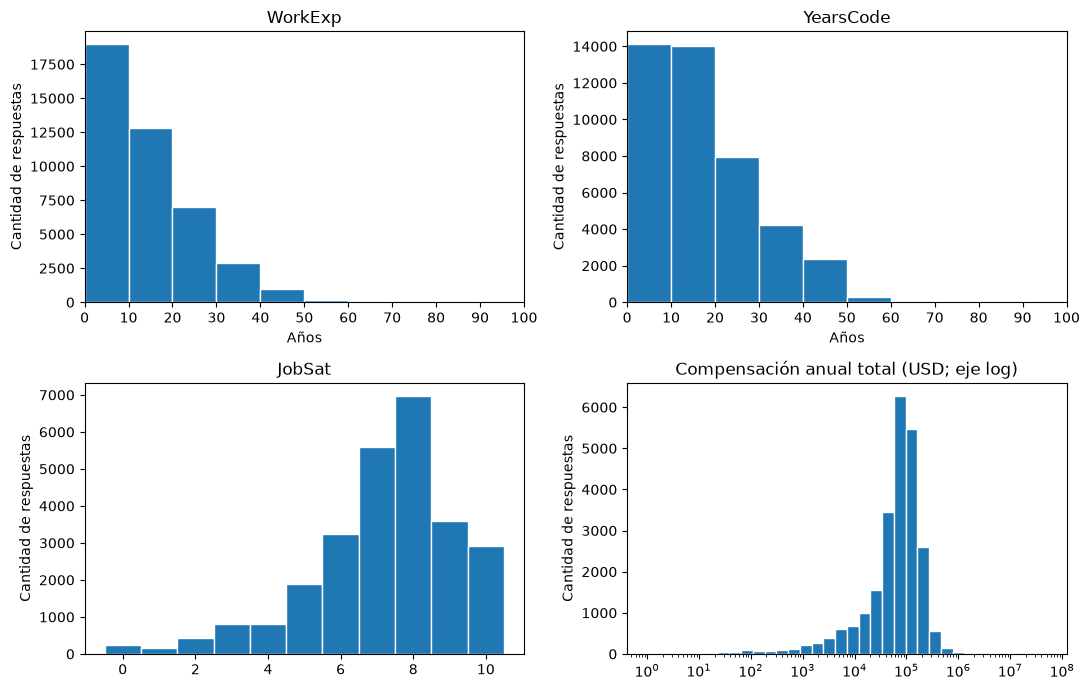

Compensaciones positivas informadas: 23947 | Representadas: 23947


In [8]:
columnas_cuantitativas = ["WorkExp", "YearsCode", "JobSat", "ToolCountWork", "ToolCountPersonal", "ConvertedCompYearly"]
figura, ejes = plt.subplots(2, 2, figsize=(11, 7))

for eje, columna in zip(ejes.flat, ["WorkExp", "YearsCode", "JobSat"]):
    intervalos = np.arange(-0.5, 11.5, 1) if columna == "JobSat" else range(0, 101, 10)
    eje.hist(datos_originales[columna].dropna(), bins=intervalos, edgecolor="white")
    if columna in ["WorkExp", "YearsCode"]:
     eje.set_xticks(range(0, 101, 10))
     eje.set_xlim(0, 100)
     eje.set_xlabel("Años")
    eje.set_title(columna)
    eje.set_ylabel("Cantidad de respuestas")

compensaciones_exploracion = datos_originales.loc[datos_originales["ConvertedCompYearly"] > 0, "ConvertedCompYearly"]
intervalos_compensacion = np.logspace(np.log10(compensaciones_exploracion.min()), np.log10(compensaciones_exploracion.max()), 35)
intervalos_compensacion[0] = compensaciones_exploracion.min()
intervalos_compensacion[-1] = compensaciones_exploracion.max()

frecuencias_compensacion, bordes_compensacion, barras_compensacion = ejes[1, 1].hist(compensaciones_exploracion, bins=intervalos_compensacion, edgecolor="white")
ejes[1, 1].set_xscale("log")
ejes[1, 1].set_title("Compensación anual total (USD; eje log)")
ejes[1, 1].set_ylabel("Cantidad de respuestas")
plt.tight_layout()
plt.show()

print(f"Compensaciones positivas informadas: {len(compensaciones_exploracion)} | Representadas: {int(frecuencias_compensacion.sum())}")


La experiencia y la compensación presentan colas hacia valores altos. La satisfacción se concentra cerca de 7–8. Usaremos medianas para describir el centro de las compensaciones.

### 1.6. Faltantes y completitud

Contamos faltantes por columna y campos completos por persona. Pueden deberse al recorrido de la encuesta o a preguntas sin contestar; no equivalen a cero ni a una respuesta negativa.

#### Campos de texto libre con mayor proporción de faltantes

Seleccionamos los campos de texto libre según los metadatos y mostramos los que superan el 95% de faltantes. Las barras horizontales permiten leer sus nombres y comparar los porcentajes sobre la base original.


Respuestas de la base original: 49191
                      Nulos      %
DatabaseHaveEntry     47041  95.63
DevEnvWantEntry       47079  95.71
TechEndorse_13_TEXT   47182  95.92
TechOppose_15_TEXT    47544  96.65
OfficeStackWantEntry  47574  96.71
DatabaseWantEntry     47658  96.88
CommPlatformHaveEntr  47715  97.00
CommPlatformWantEntr  48007  97.59
AIAgentExtWrite       48332  98.25
SO_Actions_15_TEXT    48368  98.33
AIModelsHaveEntry     48415  98.42
AIAgentKnowWrite      48425  98.44
JobSatPoints_15_TEXT  48527  98.65
AIAgentOrchWrite      48713  99.03
AIModelsWantEntry     48716  99.03
SOTagsHaveEntry       48733  99.07
SOTagsWant Entry      48761  99.13
AIAgentObsWrite       48927  99.46


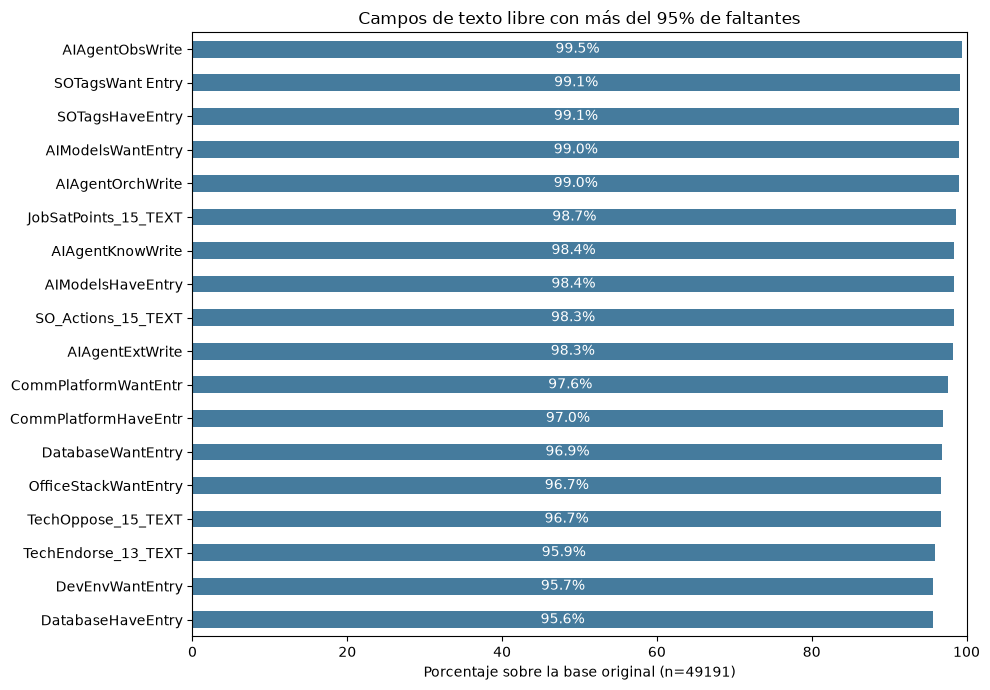

In [9]:
resumen_faltantes = pd.DataFrame({
    "Nulos": datos_originales.isna().sum(),
    "%": datos_originales.isna().mean() * 100
}).sort_values("Nulos", ascending=False)

columnas_no_numericas = datos_originales.select_dtypes(exclude="number").columns
campos_texto_abierto = metadatos.loc[
    (metadatos["type"].eq("TE") | metadatos["qname"].str.endswith("_TEXT"))
    & metadatos["qname"].isin(columnas_no_numericas),
    "qname"
]

faltantes_texto_abierto = resumen_faltantes.loc[campos_texto_abierto]
faltantes_texto_abierto = faltantes_texto_abierto[
    faltantes_texto_abierto["%"] > 95
].sort_values("%")

print("Respuestas de la base original:", len(datos_originales))
print(faltantes_texto_abierto.round(2).to_string())

eje_textos = faltantes_texto_abierto["%"].plot(
    kind="barh", figsize=(10, 7), color="#457b9d"
)
eje_textos.bar_label(
    eje_textos.containers[0], fmt="%.1f%%", label_type="center", color="white"
)
eje_textos.set_xlim(0, 100)
eje_textos.set(
    title="Campos de texto libre con más del 95% de faltantes",
    xlabel=f"Porcentaje sobre la base original (n={len(datos_originales)})",
    ylabel=""
)
plt.tight_layout()
plt.show()


Los 18 campos seleccionados presentan entre **95,6% y 99,5%** de faltantes.

#### Faltantes en las variables del análisis

Las barras horizontales permiten comparar sus porcentajes sobre la base original. Respuestas de texto como `Prefer not to say` todavía cuentan como informadas; se recodifican después.


Filas de la base original: 49191
                     Nulos  Porcentaje sobre original
WorkExp               6298                      12.80
NewRole              13664                      27.78
Country              13754                      27.96
OrgSize              15013                      30.52
RemoteWork           15411                      31.33
AIAcc                15894                      32.31
ICorPM               15948                      32.42
JobSat               22521                      45.78
ConvertedCompYearly  25244                      51.32


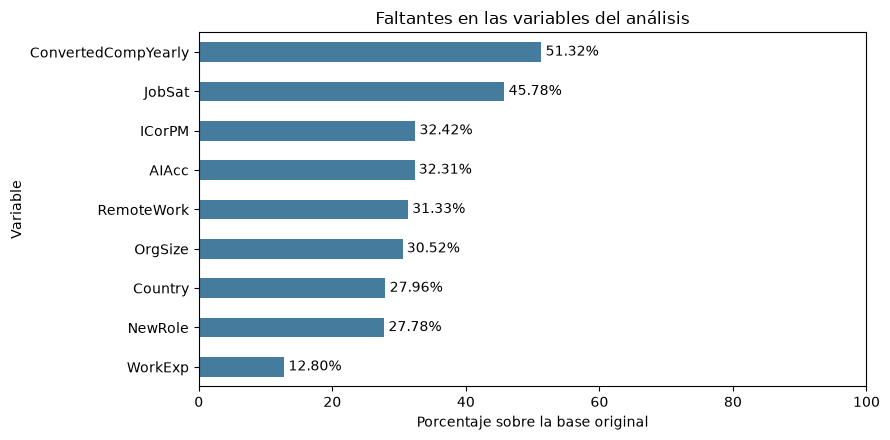

In [10]:
variables_hipotesis = ["Country", "ConvertedCompYearly", "AIAcc", "WorkExp", "OrgSize", "RemoteWork", "ICorPM", "JobSat", "NewRole"]
tabla_faltantes_analisis = pd.DataFrame({"Nulos": datos_originales[variables_hipotesis].isna().sum()})
tabla_faltantes_analisis["Porcentaje sobre original"] = tabla_faltantes_analisis["Nulos"] / len(datos_originales) * 100
tabla_faltantes_analisis = tabla_faltantes_analisis.sort_values("Porcentaje sobre original")

print("Filas de la base original:", len(datos_originales))
print(tabla_faltantes_analisis.round(2).to_string())

eje_faltantes = tabla_faltantes_analisis["Porcentaje sobre original"].plot(kind="barh", figsize=(9, 4.5), color="#457b9d")

eje_faltantes.set_xlim(0, 100)
eje_faltantes.set(title="Faltantes en las variables del análisis", xlabel="Porcentaje sobre la base original", ylabel="Variable")

eje_faltantes.bar_label(eje_faltantes.containers[0], labels=[f"{valor:.2f}%" for valor in tabla_faltantes_analisis["Porcentaje sobre original"]], padding=3)
plt.tight_layout()
plt.show()


In [11]:
respuestas_por_encuestado = datos_originales.drop("ResponseId", axis=1).notna().sum(axis=1)

print("Análisis de la cantidad de respuestas por encuestado:")
print(respuestas_por_encuestado.describe().round(1).to_string())


Análisis de la cantidad de respuestas por encuestado:
count    49191.0
mean        80.8
std         46.0
min          2.0
25%         36.0
50%         99.0
75%        120.0
max        155.0


### 1.7. Exploración de variables categóricas relevantes

Mostramos los perfiles y los diez países con más respuestas. Las barras horizontales facilitan comparar cantidades y leer las categorías. Esto permite ubicar el grupo profesional y los mercados que analizaremos.


MainBranch
I am a developer by profession                                                                37467
I am not primarily a developer, but I write code sometimes as part of my work/studies          4894
I am learning to code                                                                          2585
I code primarily as a hobby                                                                    1924
I used to be a developer by profession, but no longer am                                       1325
I work with developers or my work supports developers but am not a developer by profession      996


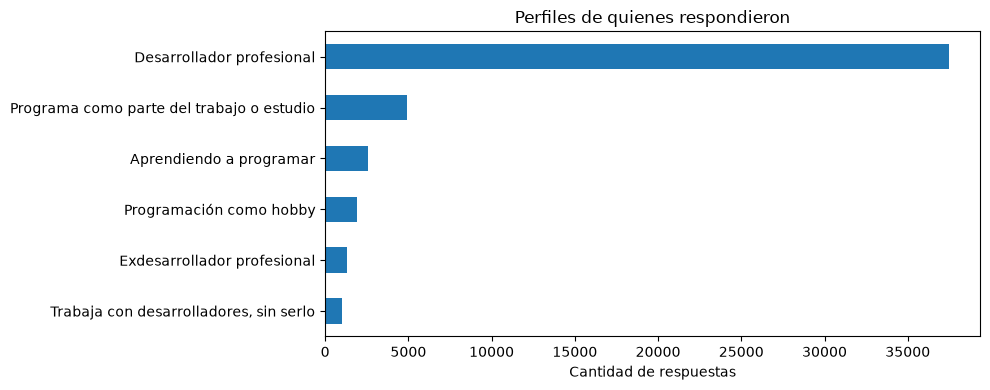

In [12]:
conteo_perfiles = datos_originales["MainBranch"].value_counts()
etiquetas_perfiles = {
    "I am a developer by profession": "Desarrollador profesional",
    "I am learning to code": "Aprendiendo a programar",
    "I am not primarily a developer, but I write code sometimes as part of my work/studies": "Programa como parte del trabajo o estudio",
    "I code primarily as a hobby": "Programación como hobby",
    "I used to be a developer by profession, but no longer am": "Exdesarrollador profesional",
    "I work with developers or my work supports developers but am not a developer by profession": "Trabaja con desarrolladores, sin serlo",
    "None of these": "Otro perfil"
}
print(conteo_perfiles.to_string())
eje = conteo_perfiles.rename(index=etiquetas_perfiles).sort_values().plot(kind="barh", figsize=(10, 4))
eje.set(title="Perfiles de quienes respondieron", xlabel="Cantidad de respuestas", ylabel="")
plt.tight_layout()
plt.show()

Country
United States of America                                7233
Germany                                                 3025
India                                                   2547
United Kingdom of Great Britain and Northern Ireland    2042
France                                                  1409
Canada                                                  1305
Ukraine                                                  964
Poland                                                   888
Netherlands                                              867
Italy                                                    835
Respuestas de Argentina: 222


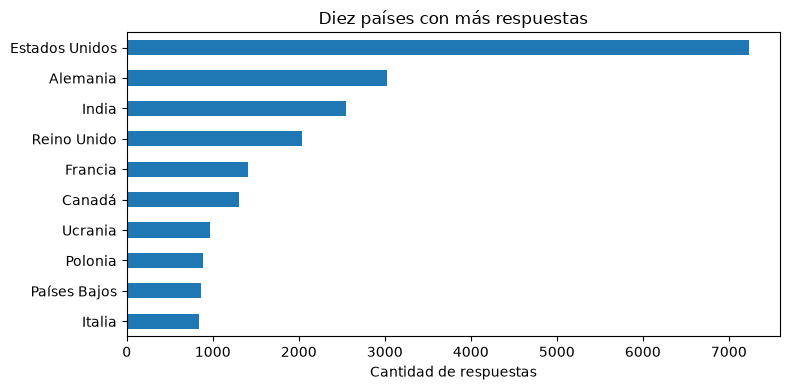

In [13]:
conteo_paises = datos_originales["Country"].value_counts().head(10)
print(conteo_paises.to_string())
print("Respuestas de Argentina:", datos_originales["Country"].eq("Argentina").sum())
etiquetas_paises = {"United States of America": "Estados Unidos", "Germany": "Alemania",
    "United Kingdom of Great Britain and Northern Ireland": "Reino Unido", "France": "Francia",
    "Canada": "Canadá", "Ukraine": "Ucrania", "Poland": "Polonia", "Netherlands": "Países Bajos", "Italy": "Italia"}
eje = conteo_paises.rename(index=etiquetas_paises).sort_values().plot(kind="barh", figsize=(8, 4))
eje.set(title="Diez países con más respuestas", xlabel="Cantidad de respuestas", ylabel="")
plt.tight_layout()
plt.show()

Predominan los desarrolladores profesionales, aunque también respondieron otros perfiles. Las preguntas laborales tienen faltantes incluso entre profesionales.

### 1.8. Detección de valores atípicos (outliers) e inconsistencias en los datos

Los boxplots resumen mediana, cuartiles y extremos de las variables medidas en años. Un punto fuera de los bigotes requiere revisión, pero no demuestra un error. También contamos respuestas extremas para conocer su frecuencia.


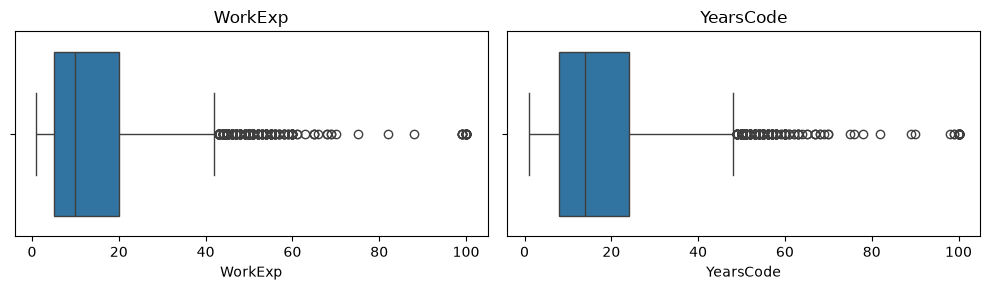

In [14]:
figura, ejes = plt.subplots(1, 2, figsize=(10, 3))

for eje, columna in zip(ejes, ["WorkExp", "YearsCode"]):
    sns.boxplot(x=datos_originales[columna], ax=eje)
    eje.set_title(columna)

plt.tight_layout()
plt.show()


In [15]:
revision_inicial = pd.Series({
    "WorkExp > 50": (datos_originales["WorkExp"] > 50).sum(),
    "YearsCode > 50": (datos_originales["YearsCode"] > 50).sum(),
    "WorkExp > YearsCode": (datos_originales["WorkExp"] > datos_originales["YearsCode"]).sum(),
    "ToolCountWork > 100": (datos_originales["ToolCountWork"] > 100).sum(),
    "Compensación > USD 1.000.000": (datos_originales["ConvertedCompYearly"] > 1000000).sum(),
    "Compensación < USD 100": (datos_originales["ConvertedCompYearly"] < 100).sum(),
})
print(revision_inicial.to_string())


WorkExp > 50                     147
YearsCode > 50                   248
WorkExp > YearsCode             3564
ToolCountWork > 100               95
Compensación > USD 1.000.000      46
Compensación < USD 100           304


`WorkExp` mide experiencia profesional general: puede superar los años programando sin ser un error. En cambio, superar la edad máxima del intervalo declarado sí constituye una contradicción.

# 2. Operaciones de limpieza
### 2.1. Columnas fuera del alcance

Trabajamos sobre una copia. Quitamos 28 campos abiertos que no se utilizarán; la selección responde al alcance del trabajo, no solo a sus faltantes.


In [16]:
datos_limpios = datos_originales.copy()
columnas_texto_libre = [
    "TechEndorse_13_TEXT", "TechOppose_15_TEXT", "JobSatPoints_15_TEXT", "SO_Actions_15_TEXT",
    "LanguagesHaveEntry", "LanguagesWantEntry", "DatabaseHaveEntry", "DatabaseWantEntry",
    "PlatformHaveEntry", "PlatformWantEntry", "WebframeHaveEntry", "WebframeWantEntry",
    "DevEnvHaveEntry", "DevEnvWantEntry", "SOTagsHaveEntry", "SOTagsWant Entry",
    "OfficeStackHaveEntry", "OfficeStackWantEntry", "CommPlatformHaveEntr", "CommPlatformWantEntr",
    "AIModelsHaveEntry", "AIModelsWantEntry", "AIAgentKnowWrite", "AIAgentOrchWrite",
    "AIAgentObsWrite", "AIAgentExtWrite", "AIExplain", "AIOpen",
]
porcentajes_faltantes_textos = datos_limpios[columnas_texto_libre].isna().mean() * 100
print(f"Campos abiertos excluidos: {len(columnas_texto_libre)}; faltantes en estas columnas entre {porcentajes_faltantes_textos.min():.1f}% y {porcentajes_faltantes_textos.max():.1f}%")
datos_limpios = datos_limpios.drop(columnas_texto_libre, axis=1)


Campos abiertos excluidos: 28; faltantes en estas columnas entre 46.0% y 99.5%


### 2.2. Inspección de registros repetidos e información disponible

Revisamos identificadores repetidos y respuestas coincidentes. Dos personas pueden contestar lo mismo: una coincidencia sin `ResponseId` no alcanza para borrar una fila.


In [17]:
print("ResponseId repetidos:", datos_originales["ResponseId"].duplicated().sum())

columnas_respuestas = datos_originales.drop("ResponseId", axis=1).columns

cantidad_duplicados = datos_originales.duplicated(subset=columnas_respuestas).sum()

print("Respuestas coincidentes sin ID:", cantidad_duplicados)


ResponseId repetidos: 0


Respuestas coincidentes sin ID: 1547


Excluimos filas que solo tienen `MainBranch` y `Age`, además del identificador. Ambas columnas están completas en el original, por eso exigimos más de dos campos informados sin contar `ResponseId`. El recuento se hace antes de quitar columnas. Este criterio no demuestra que la encuesta haya sido abandonada.


In [18]:
respuestas_validas = datos_originales.drop("ResponseId", axis=1).notna().sum(axis=1)
datos_limpios = datos_limpios[respuestas_validas > 2].copy()

print(f"Registros originales: {datos_originales.shape[0]}")
print(f"Registros conservados: {datos_limpios.shape[0]}")
print(f"Registros excluidos por falta de información adicional: {datos_originales.shape[0] - datos_limpios.shape[0]}")


Registros originales: 49191
Registros conservados: 48339
Registros excluidos por falta de información adicional: 852


### 2.3. Preselección de atributos de interés

Conservamos los atributos de las hipótesis y los necesarios para revisar inconsistencias. Incluimos los quince rankings laborales, también «Otro»; su campo de texto libre queda fuera.


In [19]:
columnas_seleccionadas = [
    "ResponseId", "MainBranch", "Age", "EdLevel", "Employment",
    "RemoteWork", "OrgSize", "ICorPM", "Industry", "DevType", "Country",

    "WorkExp", "YearsCode", "ToolCountWork", "ToolCountPersonal",
    "LanguageHaveWorkedWith", "OpSysProfessional use",

    "Currency", "CompTotal", "ConvertedCompYearly",

    "AISelect", "AIAcc", "AISent", "AIThreat",

    "JobSat", "NewRole",
    "JobSatPoints_1", "JobSatPoints_2", "JobSatPoints_3", "JobSatPoints_4",
    "JobSatPoints_5", "JobSatPoints_6", "JobSatPoints_7", "JobSatPoints_8",
    "JobSatPoints_9", "JobSatPoints_10", "JobSatPoints_11", "JobSatPoints_13",
    "JobSatPoints_14", "JobSatPoints_16", "JobSatPoints_15"
]

datos_limpios = datos_limpios[columnas_seleccionadas].copy()
print(f"Dimensiones tras la preselección de atributos: {datos_limpios.shape}")


Dimensiones tras la preselección de atributos: (48339, 41)


### 2.4. Respuestas desconocidas codificadas como texto

Mostramos las categorías originales y convertimos las respuestas desconocidas o reservadas a `NaN`, contemplando las distintas grafías de «no sé». No imputamos valores.


In [20]:
for columna in ["Age", "Employment", "OrgSize"]:
    print("\nCategorías antes de corregir:", columna)
    print(datos_limpios[columna].value_counts(dropna=False).to_string())



Categorías antes de corregir: Age
Age
25-34 years old      16228
35-44 years old      13076
18-24 years old       8950
45-54 years old       6198
55-64 years old       2605
65 years or older      932
Prefer not to say      350

Categorías antes de corregir: Employment
Employment
Employed                                                33750
Independent contractor, freelancer, or self-employed     6708
Student                                                  4428
Not employed                                             2227
Retired                                                   708
I prefer not to say                                       518

Categorías antes de corregir: OrgSize
OrgSize
NaN                                                   14161
20 to 99 employees                                     6688
100 to 499 employees                                   6109
Less than 20 employees                                 5600
10,000 or more employees                               4965


In [21]:
nulos_texto_antes = datos_limpios[["Age", "Employment", "OrgSize"]].isna().sum()
print("Valores nulos por columna antes:")
print(datos_limpios[["Age", "Employment", "OrgSize"]].isna().sum().to_string())
datos_limpios["Age"] = datos_limpios["Age"].replace("Prefer not to say", np.nan)
datos_limpios["Employment"] = datos_limpios["Employment"].replace("I prefer not to say", np.nan)
datos_limpios["OrgSize"] = datos_limpios["OrgSize"].replace(["I don’t know", "I don't know", "I don\ufffdt know"], np.nan)
print("Valores nulos por columna después:")
print(datos_limpios[["Age", "Employment", "OrgSize"]].isna().sum().to_string())


Valores nulos por columna antes:
Age               0
Employment        0
OrgSize       14161
Valores nulos por columna después:
Age             350
Employment      518
OrgSize       15093


### 2.5. Incompatibilidades y extremos

Reemplazamos por `NaN` los años de experiencia o programación que superan la edad máxima del intervalo declarado. Para edades desconocidas o de 65 años o más no asignamos un máximo. La corrección afecta al valor, no a toda la fila.


In [22]:
edad_maxima_por_intervalo = {"18-24 years old": 24,
                             "25-34 years old": 34,
                             "35-44 years old": 44,
                             "45-54 years old": 54,
                             "55-64 years old": 64}

edad_maxima = datos_limpios["Age"].map(edad_maxima_por_intervalo)
inconsistentes_workexp = datos_limpios["WorkExp"] > edad_maxima
inconsistentes_yearscode = datos_limpios["YearsCode"] > edad_maxima
print("Valores incompatibles: WorkExp =", inconsistentes_workexp.sum(), "| YearsCode =", inconsistentes_yearscode.sum())

datos_limpios.loc[inconsistentes_workexp, "WorkExp"] = np.nan
datos_limpios.loc[inconsistentes_yearscode, "YearsCode"] = np.nan

casos_experiencia_dudosa = datos_limpios[(datos_limpios["WorkExp"] >= 100) | (datos_limpios["YearsCode"] >= 100)].copy()
ids_experiencia_dudosa = casos_experiencia_dudosa["ResponseId"]

print("Registros con un siglo declarado que requieren analisis:", len(casos_experiencia_dudosa))


Valores incompatibles: WorkExp = 53 | YearsCode = 54
Registros con un siglo declarado que requieren analisis: 9


Quedan nueve registros con 100 años declarados en experiencia o programación que no se resuelven mediante el límite de edad. Los conservamos señalados para revisar su influencia donde participen.


#### Cantidades de herramientas declaradas

La pregunta cuenta aplicaciones o plataformas usadas regularmente en el rol principal. Tratamos `ToolCountWork = 10000` como desconocido por su magnitud dudosa y porque no podemos reconstruir la respuesta correcta. Conservamos las filas y sus demás datos.


In [23]:
pregunta_herramientas = metadatos.loc[metadatos["qname"].eq("ToolCountWork"), "question"].iloc[0]
print("Pregunta original de ToolCountWork:", pregunta_herramientas)

herramientas_trabajo_dudosas = datos_limpios["ToolCountWork"].eq(10000)
casos_herramientas = datos_limpios.loc[herramientas_trabajo_dudosas].copy()
datos_limpios.loc[herramientas_trabajo_dudosas, "ToolCountWork"] = np.nan
tabla_revision_herramientas = pd.DataFrame({"ResponseId": casos_herramientas["ResponseId"], "ToolCountWork antes": casos_herramientas["ToolCountWork"], "ToolCountWork después": datos_limpios.loc[casos_herramientas.index, "ToolCountWork"], "ToolCountPersonal (se conserva)": casos_herramientas["ToolCountPersonal"]})
print("Valores 10000 de ToolCountWork convertidos a faltantes:", int(herramientas_trabajo_dudosas.sum()))

print(tabla_revision_herramientas.to_string(index=False))


Pregunta original de ToolCountWork: For your <b>primary work role</b> (student, developer, or technologist) over the past year:
<br><br>Excluding general operating systems (like Windows or macOS) and web browsers, <b>how many distinct software applications or platforms</b> did you regularly use to create, analyze, manage, or share information in order to do your job?

Please enter a whole number below with no punctuation, or leave blank.
Valores 10000 de ToolCountWork convertidos a faltantes: 15
 ResponseId  ToolCountWork antes  ToolCountWork después  ToolCountPersonal (se conserva)
       5749              10000.0                    NaN                              2.0
       6786              10000.0                    NaN                           1000.0
       6874              10000.0                    NaN                             10.0
       6990              10000.0                    NaN                           1000.0
      21456              10000.0                    Na

La tabla permite comprobar el reemplazo de los 15 valores. Las herramientas personales y las demás respuestas no se modifican.


### 2.6. Comprobación de las correcciones

Verificamos las incompatibilidades restantes y comparamos antes y después con boxplots de escala común. Los conteos permiten reconocer las correcciones aunque las cajas cambien poco.


In [24]:
print("WorkExp incompatible restante:", (datos_limpios["WorkExp"] > edad_maxima).sum())
print("YearsCode incompatible restante:", (datos_limpios["YearsCode"] > edad_maxima).sum())
print("JobSat fuera de 0–10:", (~datos_limpios["JobSat"].between(0, 10) & datos_limpios["JobSat"].notna()).sum())


WorkExp incompatible restante: 0
YearsCode incompatible restante: 0
JobSat fuera de 0–10: 0


 Variable  Antes: valores informados  Después: valores informados  Valores anulados
  WorkExp                      42893                        42840                53
YearsCode                      43042                        42988                54


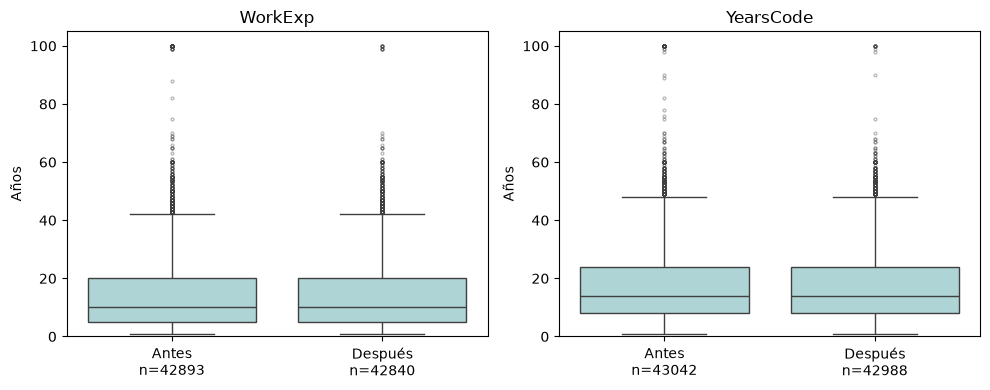

In [25]:
control_correcciones = []

figura, ejes = plt.subplots(1, 2, figsize=(10, 4))

for eje, columna in zip(ejes, ["WorkExp", "YearsCode"]):
    antes = datos_originales.loc[datos_limpios.index, columna]
    despues = datos_limpios[columna]
    comparacion = pd.DataFrame({"Antes": antes, "Después": despues})
    sns.boxplot(data=comparacion, color="#a8dadc", flierprops={"markersize": 2, "alpha": 0.35}, ax=eje)
    eje.set_ylim(0, 105)
    eje.set_xticks([0, 1], labels=[f"Antes\nn={antes.notna().sum()}", f"Después\nn={despues.notna().sum()}"])
    eje.set(title=columna, ylabel="Años")
    control_correcciones.append({"Variable": columna, "Antes: valores informados": int(antes.notna().sum()), "Después: valores informados": int(despues.notna().sum()), "Valores anulados": int((antes.notna() & despues.isna()).sum())})

tabla_control_correcciones = pd.DataFrame(control_correcciones)

print(tabla_control_correcciones.to_string(index=False))
plt.tight_layout()
plt.show()


### 2.7. Orden de las categorías de confianza en IA

Creamos `confianza_ia_ordinal`: de 1 (desconfía mucho) a 5 (confía mucho). Representa un orden, sin suponer distancias iguales. Se utilizará en Spearman; conservamos `AIAcc`.


In [26]:
mapa_confianza_ordinal = {
    "Highly distrust": 1,
    "Somewhat distrust": 2,
    "Neither trust nor distrust": 3,
    "Somewhat trust": 4,
    "Highly trust": 5
}
print("\nConteo de aiacc:")
print(datos_limpios["AIAcc"].value_counts().sort_index())
datos_limpios["confianza_ia_ordinal"] = datos_limpios["AIAcc"].map(mapa_confianza_ordinal)
print("\nConteo de confianza_ia_ordinal:")
print(datos_limpios["confianza_ia_ordinal"].value_counts().sort_index())



Conteo de aiacc:
AIAcc
Highly distrust               6533
Highly trust                  1048
Neither trust nor distrust    7162
Somewhat distrust             8685
Somewhat trust                9869
Name: count, dtype: int64

Conteo de confianza_ia_ordinal:
confianza_ia_ordinal
1.0    6533
2.0    8685
3.0    7162
4.0    9869
5.0    1048
Name: count, dtype: int64


### 2.8. Situación de cambio laboral

Agrupamos `NewRole` en no consideró cambiar, lo consideró y ya transicionó. Mantenemos separadas la intención y la transición, y conservamos la respuesta original.


In [27]:
mapa_situacion_cambio = {
    "I have neither consider or transitioned into a new career or industry": "No considero",
    "I have somewhat considered changing my career and/or the industry I work in": "Considero",
    "I have strongly considered changing my career and/or the industry I work in": "Considero",
    "I have transitioned into a new career and/or industry voluntarily": "Transiciono",
    "I have transitioned into a new career and/or industry involuntarily": "Transiciono"
}
datos_limpios["situacion_cambio_laboral"] = datos_limpios["NewRole"].map(mapa_situacion_cambio)
print("Conteo de situacion_cambio_laboral:")
print(datos_limpios["situacion_cambio_laboral"].value_counts(dropna=False))


Conteo de situacion_cambio_laboral:
situacion_cambio_laboral
No considero    16205
Considero       15486
NaN             12812
Transiciono      3836
Name: count, dtype: int64


### 2.9. Resumen de las operaciones de limpieza

La tabla distingue filas excluidas, valores corregidos y columnas seleccionadas o creadas. Sus cantidades tienen unidades diferentes; no deben sumarse como si todas fueran personas eliminadas.


In [28]:
nulos_texto_despues = datos_limpios[["Age", "Employment", "OrgSize"]].isna().sum()
recodificados_texto = nulos_texto_despues - nulos_texto_antes

variables_creadas = [columna for columna in datos_limpios.columns if columna not in datos_originales.columns]

resumen_limpieza = pd.DataFrame([
    {"Operación": "Registros sin información adicional excluidos", "Cantidad": len(datos_originales) - len(datos_limpios), "Unidad": "filas"},
    {"Operación": "Campos abiertos fuera del alcance", "Cantidad": len(columnas_texto_libre), "Unidad": "columnas excluidas"},
    {"Operación": "Atributos originales seleccionados", "Cantidad": len(columnas_seleccionadas), "Unidad": "columnas conservadas"},
    {"Operación": "Edad desconocida convertida a faltante", "Cantidad": recodificados_texto["Age"], "Unidad": "valores"},
    {"Operación": "Empleo desconocido convertido a faltante", "Cantidad": recodificados_texto["Employment"], "Unidad": "valores"},
    {"Operación": "Tamaño de empresa desconocido convertido a faltante", "Cantidad": recodificados_texto["OrgSize"], "Unidad": "valores"},
    {"Operación": "WorkExp incompatible con edad convertido a faltante", "Cantidad": inconsistentes_workexp.sum(), "Unidad": "valores"},
    {"Operación": "YearsCode incompatible con edad convertido a faltante", "Cantidad": inconsistentes_yearscode.sum(), "Unidad": "valores"},
    {"Operación": "ToolCountWork = 10000 convertido a faltante", "Cantidad": herramientas_trabajo_dudosas.sum(), "Unidad": "valores"},
    {"Operación": "Variables derivadas creadas", "Cantidad": len(variables_creadas), "Unidad": "columnas"},
])

print("Base original:", datos_originales.shape, "| Base limpia:", datos_limpios.shape)
print(resumen_limpieza.to_string(index=False))
print("Variables creadas:", variables_creadas)


Base original: (49191, 172) | Base limpia: (48339, 43)
                                            Operación  Cantidad               Unidad
        Registros sin información adicional excluidos       852                filas
                    Campos abiertos fuera del alcance        28   columnas excluidas
                   Atributos originales seleccionados        41 columnas conservadas
               Edad desconocida convertida a faltante       350              valores
             Empleo desconocido convertido a faltante       518              valores
  Tamaño de empresa desconocido convertido a faltante       932              valores
  WorkExp incompatible con edad convertido a faltante        53              valores
YearsCode incompatible con edad convertido a faltante        54              valores
          ToolCountWork = 10000 convertido a faltante        15              valores
                          Variables derivadas creadas         2             columnas
Variables 

#### Guardado del conjunto limpio

Guardamos la base limpia. Los filtros de perfil y de respuestas disponibles se aplicarán en cada hipótesis.


In [29]:
print("Dataset Base:", datos_originales.shape)
print("Base limpia:", datos_limpios.shape)
datos_limpios.to_pickle("dataset_limpio.pkl")


Dataset Base: (49191, 172)
Base limpia: (48339, 43)


# 3. Hipótesis del grupo

Estudiaremos desarrolladores profesionales, con las respuestas disponibles en cada análisis.

### 3.1. Univariada: confianza en la precisión de la IA

**Planteo:** menos del 10% de quienes respondieron `AIAcc` tiene confianza alta y más del 40% expresa desconfianza.

**Justificación:** incorporar IA al desarrollo no implica confiar en todas sus respuestas. Nos interesa describir cuánto pesa cada postura. Los límites de 10% y 40% fueron elegidos por el grupo.

### 3.2. Bivariada: compensación en Estados Unidos e India

**Planteo:** la mediana de la compensación anual total en USD difiere entre los desarrolladores profesionales de Estados Unidos y los de India.

**Justificación:** los dos mercados tienen condiciones de contratación y remuneración distintas. Comparar sus compensaciones en una misma moneda permite dimensionar la brecha nominal. Elegimos la mediana porque las distribuciones son asimétricas y tienen importes extremos.

### 3.3. Multivariada: trabajo remoto según tamaño de empresa

**Planteo.** Entre los desarrolladores profesionales de Estados Unidos, la probabilidad de declarar trabajo totalmente remoto se relaciona con el tamaño de la empresa, teniendo en cuenta el rol profesional, la experiencia y el sector en el que trabajan.

Nos pareció importante incluir el sector porque en software, salud o gobierno pueden existir condiciones de trabajo distintas. También puede cambiar la composición de roles y de experiencia entre empresas de distinto tamaño. Nos quedamos dentro de Estados Unidos para comparar respuestas de un mismo mercado laboral.


### 3.4. Grupo de análisis

Seleccionamos desarrolladores profesionales mediante `MainBranch`. Cada hipótesis utiliza las respuestas disponibles para sus variables y presenta su propio tamaño.


In [30]:
perfil_profesional = "I am a developer by profession"

datos_profesionales = datos_limpios[
    datos_limpios["MainBranch"].eq(perfil_profesional)
].copy()

print(
    "Registros en la base limpia:", len(datos_limpios),
    "| Desarrolladores profesionales:", len(datos_profesionales)
)

Registros en la base limpia: 48339 | Desarrolladores profesionales: 36896


# 4. Contrastes de hipótesis

Fijamos **α = 0,05**: rechazamos H₀ si p < α. No rechazarla no demuestra que sea verdadera.

Usamos una respuesta por persona y asumimos independencia entre encuestados. Los tests no corrigen la selección voluntaria ni los faltantes de la encuesta.


In [31]:
nivel_significancia = 0.05

orden_confianza = ["Highly distrust", "Somewhat distrust", "Neither trust nor distrust", "Somewhat trust", "Highly trust"]
etiquetas_confianza = ["Desconfía mucho", "Desconfía algo", "Neutral", "Confía algo", "Confía mucho"]

def formatear_valor_p(valor):
    return "<0,001" if valor < 0.001 else f"{valor:.3f}"

print("Desarrolladores profesionales disponibles:", len(datos_profesionales))


Desarrolladores profesionales disponibles: 36896


### 4.1. Univariada: confianza en la precisión de la IA

Agrupamos `AIAcc` en confianza alta (`Highly trust`), desconfianza (`Somewhat distrust` y `Highly distrust`) y resto. Usamos profesionales con respuesta informada y aplicamos dos pruebas Z de una proporción:

- Confianza alta: H₀: p = 0,10; H₁: p < 0,10.
- Desconfianza: H₀: p = 0,40; H₁: p > 0,40.

Estadístico: Z = (p̂ − p₀) / √(p₀(1 − p₀)/n).

Comprobamos n·p₀ ≥ 10 y n·(1 − p₀) ≥ 10, con categorías excluyentes. El planteo completo requiere rechazar ambas H₀. Las barras muestran la composición y comparan los porcentajes con los límites propuestos.


In [32]:
def test_z_proporcion(x, n, p0, alternativa):
    p_hat = x / n
    z = (p_hat - p0) / np.sqrt(p0 * (1 - p0) / n)

    if alternativa == "menor":
        p = stats.norm.cdf(z)
    elif alternativa == "mayor":
        p = stats.norm.sf(z)
    else:
        p = 2 * stats.norm.sf(abs(z))

    return p_hat, z, p


aiacc = datos_profesionales["AIAcc"].dropna()
n = len(aiacc)

x_alta = int(aiacc.eq("Highly trust").sum())
x_desconf = int(
    aiacc.isin(["Highly distrust", "Somewhat distrust"]).sum()
)

control_muestra = pd.DataFrame({
    "Condición": ["Confianza alta", "Desconfianza"],
    "p0": [0.10, 0.40],
    "n·p0": [n * 0.10, n * 0.40],
    "n·(1−p0)": [n * 0.90, n * 0.60]
})

print(control_muestra.round(2).to_string(index=False))

for p0 in [0.10, 0.40]:
    assert n * p0 >= 10 and n * (1 - p0) >= 10, (
        "No se cumple el criterio para la aproximación normal."
    )

p1_hat, z1, pv1 = test_z_proporcion(x_alta, n, 0.10, "menor")
p2_hat, z2, pv2 = test_z_proporcion(x_desconf, n, 0.40, "mayor")

cantidad_respuestas_confianza = n
proporcion_confianza_alta = p1_hat
proporcion_desconfianza = p2_hat

resultado_univariada = pd.DataFrame({
    "Condición": ["Confianza alta < 10%", "Desconfianza > 40%"],
    "Cantidad": [x_alta, x_desconf],
    "p0": [0.10, 0.40],
    "Observado (%)": [100 * p1_hat, 100 * p2_hat],
    "z": [z1, z2],
    "p-valor": [
        formatear_valor_p(pv1),
        formatear_valor_p(pv2)
    ],
    "Se rechaza H0": [
        pv1 < nivel_significancia,
        pv2 < nivel_significancia
    ]
})

print(f"\nRespuestas válidas: {n}")
print(
    "Profesionales sin AIAcc:",
    datos_profesionales["AIAcc"].isna().sum()
)
print(resultado_univariada.round(3).to_string(index=False))

     Condición  p0    n·p0  n·(1−p0)
Confianza alta 0.1  2573.9   23165.1
  Desconfianza 0.4 10295.6   15443.4

Respuestas válidas: 25739
Profesionales sin AIAcc: 11157
           Condición  Cantidad  p0  Observado (%)       z p-valor  Se rechaza H0
Confianza alta < 10%       706 0.1          2.743 -38.809  <0,001           True
  Desconfianza > 40%     11825 0.4         45.942  19.459  <0,001           True


                Cantidad  Porcentaje
Confianza alta       706        2.74
Desconfianza       11825       45.94
Resto              13208       51.32


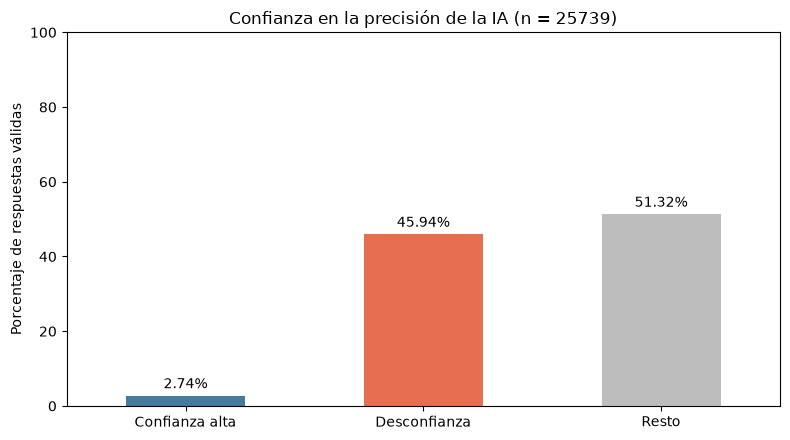

In [33]:
tabla_confianza_agrupada = pd.DataFrame({
    "Cantidad": [x_alta, x_desconf, n - x_alta - x_desconf]
}, index=["Confianza alta", "Desconfianza", "Resto"])

tabla_confianza_agrupada["Porcentaje"] = (
    tabla_confianza_agrupada["Cantidad"] / n * 100
)

print(tabla_confianza_agrupada.round(2).to_string())

eje = tabla_confianza_agrupada["Porcentaje"].plot(
    kind="bar",
    figsize=(8, 4.5),
    color=["#457b9d", "#e76f51", "#bdbdbd"],
    rot=0
)

eje.bar_label(eje.containers[0], fmt="%.2f%%", padding=3)
eje.set_title(f"Confianza en la precisión de la IA (n = {n})")
eje.set_xlabel("")
eje.set_ylabel("Porcentaje de respuestas válidas")
eje.set_ylim(0, 100)

plt.tight_layout()
plt.show()

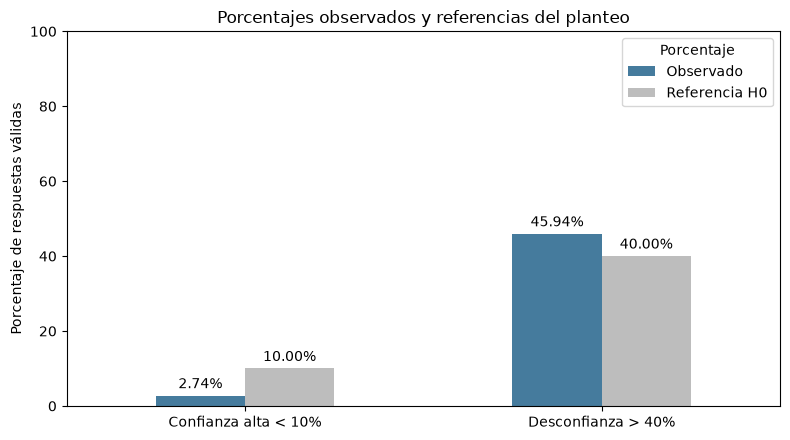

In [34]:
comparacion_confianza = resultado_univariada.set_index("Condición")[
    ["Observado (%)", "p0"]
].copy()

comparacion_confianza["p0"] = comparacion_confianza["p0"] * 100
comparacion_confianza.columns = ["Observado", "Referencia H0"]

eje = comparacion_confianza.plot(
    kind="bar",
    figsize=(8, 4.5),
    color=["#457b9d", "#bdbdbd"],
    rot=0
)

for barras in eje.containers:
    eje.bar_label(barras, fmt="%.2f%%", padding=3)

eje.set_title("Porcentajes observados y referencias del planteo")
eje.set_xlabel("")
eje.set_ylabel("Porcentaje de respuestas válidas")
eje.set_ylim(0, 100)
eje.legend(title="Porcentaje")

plt.tight_layout()
plt.show()

In [35]:
cumple_hipotesis_confianza = bool(
    resultado_univariada["Se rechaza H0"].all()
)

if cumple_hipotesis_confianza:
    print(
        "Ambos tests rechazan H0: encontramos respaldo estadístico "
        "para una proporción de confianza alta inferior al 10% "
        "y una proporción de desconfianza superior al 40%."
    )
else:
    print(
        "Los resultados no aportan evidencia suficiente "
        "para respaldar simultáneamente ambas condiciones."
    )


Ambos tests rechazan H0: encontramos respaldo estadístico para una proporción de confianza alta inferior al 10% y una proporción de desconfianza superior al 40%.


### 4.2. Brecha de compensación entre Estados Unidos e India

Agrupamos a los profesionales por `Country` y conservamos las compensaciones anuales informadas y positivas de `ConvertedCompYearly`. Comparamos los montos en USD nominales.

**H₀:** las medianas poblacionales de compensación anual son iguales.

**H₁:** las medianas poblacionales de compensación anual son distintas.


In [36]:
datos_mercados = datos_profesionales.loc[
    datos_profesionales["Country"].isin(["United States of America", "India"])
    & datos_profesionales["ConvertedCompYearly"].gt(0)
].copy()

compensaciones_estados_unidos = datos_mercados.loc[
    datos_mercados["Country"].eq("United States of America"), "ConvertedCompYearly"
]
compensaciones_india = datos_mercados.loc[
    datos_mercados["Country"].eq("India"), "ConvertedCompYearly"
]

resumen_mercados = datos_mercados.groupby("Country")["ConvertedCompYearly"].agg(
    n="count", mediana_USD="median"
)
cociente_medianas_mercados = compensaciones_estados_unidos.median() / compensaciones_india.median()

print(resumen_mercados.round(2).to_string())
print(f"Cociente observado de medianas (Estados Unidos / India): {cociente_medianas_mercados:.2f}")


                             n  mediana_USD
Country                                    
India                      943      18598.0
United States of America  4376     150000.0
Cociente observado de medianas (Estados Unidos / India): 8.07


#### Revisión de normalidad

Revisamos cada país con Shapiro-Wilk (H₀: distribución normal) y gráficos Q-Q. Ambos grupos tienen menos de 5.000 respuestas, por lo que utilizamos todos sus valores.


          País    n     W p-valor  Se rechaza normalidad
Estados Unidos 4376 0.358  <0,001                   True
         India  943 0.065  <0,001                   True


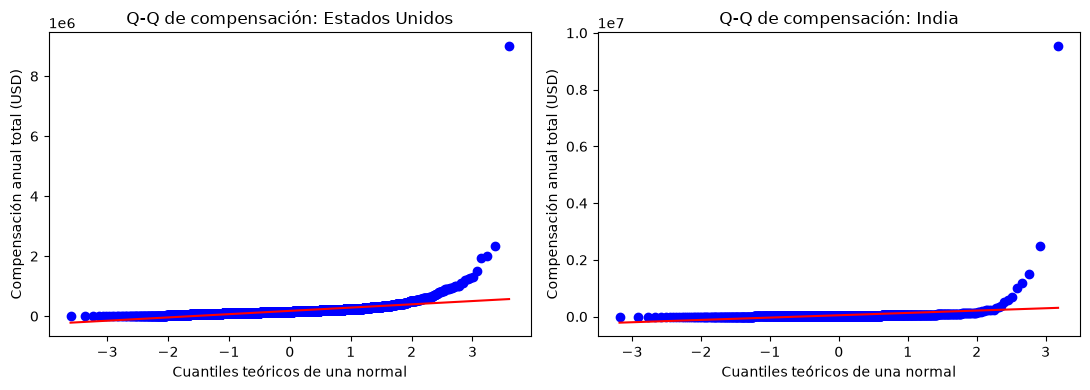

In [37]:
resultados_normalidad = []

for pais, compensaciones in [
    ("Estados Unidos", compensaciones_estados_unidos),
    ("India", compensaciones_india)
]:
    resultado = stats.shapiro(compensaciones)

    resultados_normalidad.append({
        "País": pais,
        "n": len(compensaciones),
        "W": resultado.statistic,
        "p-valor": formatear_valor_p(resultado.pvalue),
        "Se rechaza normalidad": resultado.pvalue < nivel_significancia
    })

tabla_normalidad_mercados = pd.DataFrame(resultados_normalidad)
print(tabla_normalidad_mercados.round(3).to_string(index=False))

figura, ejes = plt.subplots(1, 2, figsize=(11, 4))

stats.probplot(
    compensaciones_estados_unidos,
    dist="norm",
    plot=ejes[0]
)

stats.probplot(
    compensaciones_india,
    dist="norm",
    plot=ejes[1]
)

for eje, pais in zip(ejes, ["Estados Unidos", "India"]):
    eje.set_title(f"Q-Q de compensación: {pais}")
    eje.set_xlabel("Cuantiles teóricos de una normal")
    eje.set_ylabel("Compensación anual total (USD)")

plt.tight_layout()
plt.show()


#### Revisión de igualdad de varianzas

Aplicamos Levene con centro en la mediana sobre las dos series en USD. H₀ plantea igualdad de varianzas.

En el gráfico, cada punto es una respuesta. El eje horizontal muestra la media de su país y el vertical, el residuo estudentizado. Los dos paneles usan las mismas observaciones y el de la derecha amplía la zona central. El gráfico ayuda a ver la dispersión. La decisión sobre las varianzas se toma con Levene.


Levene: W = 18.285
p-valor: <0,001
Se rechaza H0: hay evidencia de diferencias de varianza.


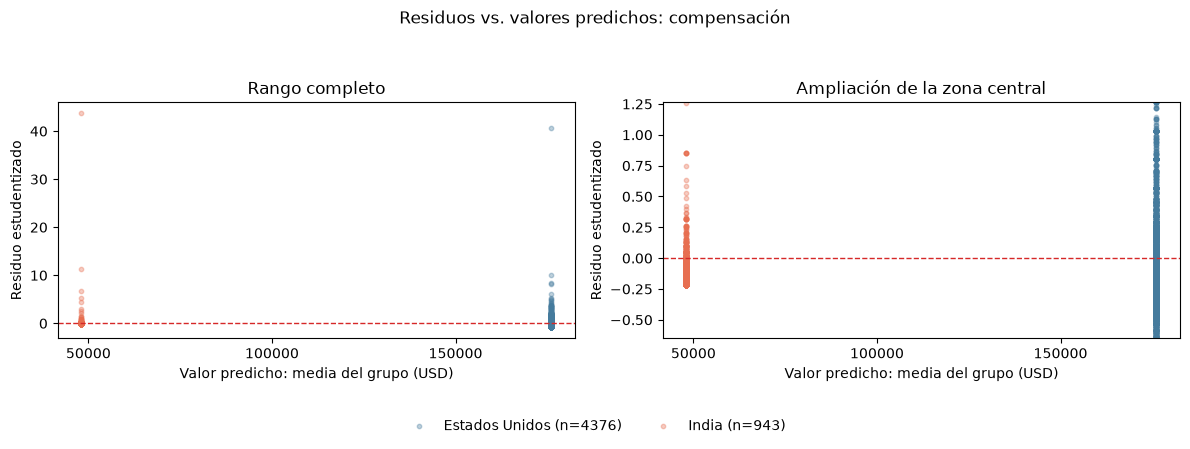

In [38]:
resultado_levene_mercados = stats.levene(
    compensaciones_estados_unidos,
    compensaciones_india,
    center="median"
)

print(f"Levene: W = {resultado_levene_mercados.statistic:.3f}")
print(f"p-valor: {formatear_valor_p(resultado_levene_mercados.pvalue)}")

if resultado_levene_mercados.pvalue < nivel_significancia:
    print("Se rechaza H0: hay evidencia de diferencias de varianza.")
else:
    print("No hay evidencia suficiente para rechazar la igualdad de varianzas.")

datos_residuos_mercados = datos_mercados[["Country", "ConvertedCompYearly"]].copy()

resumen_ajuste_mercados = datos_residuos_mercados.groupby("Country")[
    "ConvertedCompYearly"
].agg(n="count", media_USD="mean")

datos_residuos_mercados["Predicho"] = datos_residuos_mercados["Country"].map(
    resumen_ajuste_mercados["media_USD"]
)
datos_residuos_mercados["Residuo"] = (
    datos_residuos_mercados["ConvertedCompYearly"] - datos_residuos_mercados["Predicho"]
)
varianza_residual_mercados = (datos_residuos_mercados["Residuo"] ** 2).sum() / (
    len(datos_residuos_mercados) - len(resumen_ajuste_mercados)
)
datos_residuos_mercados["Residuo_estudentizado"] = datos_residuos_mercados["Residuo"] / np.sqrt(
    varianza_residual_mercados * (
        1 - 1 / datos_residuos_mercados["Country"].map(resumen_ajuste_mercados["n"])
    )
)

figura_mercados, ejes_mercados = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for pais, etiqueta, color in [
    ("United States of America", "Estados Unidos", "#457b9d"),
    ("India", "India", "#e76f51")
]:
    grupo_mercado = datos_residuos_mercados[datos_residuos_mercados["Country"].eq(pais)]
    for eje_mercado in ejes_mercados:
        eje_mercado.scatter(
            grupo_mercado["Predicho"], grupo_mercado["Residuo_estudentizado"],
            s=10, alpha=0.35, color=color, label=f"{etiqueta} (n={len(grupo_mercado)})"
        )

for eje_mercado in ejes_mercados:
    eje_mercado.axhline(0, color="#d62828", linestyle="--", linewidth=1)
    eje_mercado.set(xlabel="Valor predicho: media del grupo (USD)", ylabel="Residuo estudentizado")
    eje_mercado.ticklabel_format(axis="x", style="plain", useOffset=False)
    eje_mercado.locator_params(axis="x", nbins=4)

ejes_mercados[0].set_title("Rango completo")
limites_ampliacion_mercados = datos_residuos_mercados["Residuo_estudentizado"].quantile([0.025, 0.975])
ejes_mercados[1].set_ylim(limites_ampliacion_mercados.iloc[0], limites_ampliacion_mercados.iloc[1])
ejes_mercados[1].set_title("Ampliación de la zona central")

elementos_mercados, etiquetas_mercados = ejes_mercados[0].get_legend_handles_labels()
figura_mercados.legend(
    elementos_mercados, etiquetas_mercados, loc="lower center", ncol=2,
    frameon=False, bbox_to_anchor=(0.5, 0.01)
)
figura_mercados.suptitle("Residuos vs. valores predichos: compensación")
plt.tight_layout(rect=[0, 0.12, 1, 0.93])
plt.show()


#### Prueba de la mediana

Elegimos la prueba de la mediana porque el planteo compara medianas de grupos independientes. Tomamos la mediana conjunta y contamos, para cada país, cuántos valores quedan por encima y cuántos quedan por debajo o igual. Aplicamos el chi-cuadrado a esa tabla y comprobamos que las frecuencias esperadas sean al menos 5. Shapiro y Levene describen los datos, pero la prueba elegida admite distribuciones asimétricas y varianzas distintas.


In [39]:
resultado_mediana_mercados = stats.median_test(
    compensaciones_estados_unidos, compensaciones_india,
    ties="below", correction=False
)
valor_p_mediana_mercados = resultado_mediana_mercados.pvalue

tabla_mediana_mercados = pd.DataFrame(
    resultado_mediana_mercados.table,
    index=["Por encima", "Por debajo o igual"],
    columns=["Estados Unidos", "India"]
)

frecuencias_esperadas_mercados = stats.chi2_contingency(
    tabla_mediana_mercados, correction=False
).expected_freq

tabla_esperadas_mercados = pd.DataFrame(
    frecuencias_esperadas_mercados,
    index=tabla_mediana_mercados.index,
    columns=tabla_mediana_mercados.columns
)

frecuencias_adecuadas = frecuencias_esperadas_mercados.min() >= 5
apoyo_hipotesis_mercados = frecuencias_adecuadas and valor_p_mediana_mercados < nivel_significancia

print(f"Mediana conjunta: USD {resultado_mediana_mercados.median:,.0f}")
print("\nFrecuencias observadas")
print(tabla_mediana_mercados.to_string())
print("\nFrecuencias esperadas")
print(tabla_esperadas_mercados.round(2).to_string())
print(f"\nEsperada mínima: {frecuencias_esperadas_mercados.min():.2f} (mínimo 5)")
print(f"Chi-cuadrado: {resultado_mediana_mercados.statistic:.2f}")
print(f"p-valor: {formatear_valor_p(valor_p_mediana_mercados)}")


Mediana conjunta: USD 136,000

Frecuencias observadas
                    Estados Unidos  India
Por encima                    2628     22
Por debajo o igual            1748    921

Frecuencias esperadas
                    Estados Unidos   India
Por encima                 2180.18  469.82
Por debajo o igual         2195.82  473.18

Esperada mínima: 469.82 (mínimo 5)
Chi-cuadrado: 1033.96
p-valor: <0,001


#### Revisión de extremos y control de sensibilidad

Revisamos el máximo de cada país y calculamos los límites Q1 − 1,5 × IQR y Q3 + 1,5 × IQR por separado. Repetimos el contraste sin las señales IQR como control auxiliar. El análisis principal conserva todos los casos: una señal estadística no demuestra un error.


In [40]:
maximos_mercados = datos_mercados.sort_values(
    ["Country", "ConvertedCompYearly", "ResponseId"],
    ascending=[True, False, True]
).groupby("Country").head(1)

print("Mayor importe de cada país:")
print(maximos_mercados[[
    "Country", "ResponseId", "Currency", "CompTotal",
    "ConvertedCompYearly", "WorkExp"
]].to_string(index=False))

revision_compensacion = []
partes_sensibilidad = []

for pais, datos_pais in datos_mercados.groupby("Country"):
    compensaciones_pais = datos_pais["ConvertedCompYearly"]

    primer_cuartil, tercer_cuartil = compensaciones_pais.quantile([0.25, 0.75])
    rango_intercuartil = tercer_cuartil - primer_cuartil

    limite_inferior = primer_cuartil - 1.5 * rango_intercuartil
    limite_superior = tercer_cuartil + 1.5 * rango_intercuartil

    dentro_limites = compensaciones_pais.between(
        limite_inferior, limite_superior
    )

    revision_compensacion.append({
        "País": pais,
        "Q1": primer_cuartil,
        "Q3": tercer_cuartil,
        "Limite inferior": limite_inferior,
        "Limite superior": limite_superior,
        "Señales IQR": int((~dentro_limites).sum())
    })

    partes_sensibilidad.append(datos_pais.loc[dentro_limites])

revision_compensacion = pd.DataFrame(
    revision_compensacion
).set_index("País")

paises_sensibilidad = pd.concat(partes_sensibilidad)

print(revision_compensacion.round(2).to_string())

compensaciones_usa_sensibilidad = paises_sensibilidad.loc[
    paises_sensibilidad["Country"].eq("United States of America"),
    "ConvertedCompYearly"
]

compensaciones_india_sensibilidad = paises_sensibilidad.loc[
    paises_sensibilidad["Country"].eq("India"),
    "ConvertedCompYearly"
]

resultado_mediana_sensibilidad = stats.median_test(
    compensaciones_usa_sensibilidad,
    compensaciones_india_sensibilidad,
    ties="below",
    correction=False
)

valor_p_mercados_sensibilidad = resultado_mediana_sensibilidad.pvalue

cociente_medianas_sensibilidad = (
    compensaciones_usa_sensibilidad.median()
    / compensaciones_india_sensibilidad.median()
)

tabla_control_mercados = pd.DataFrame({
    "n": [len(datos_mercados), len(paises_sensibilidad)],
    "Cociente de medianas": [
        cociente_medianas_mercados,
        cociente_medianas_sensibilidad
    ],
    "p-valor": [
        formatear_valor_p(valor_p_mediana_mercados),
        formatear_valor_p(valor_p_mercados_sensibilidad)
    ]
}, index=["Todos los casos", "Control sin señales IQR"])

print(tabla_control_mercados.round(2).to_string())


Mayor importe de cada país:
                 Country  ResponseId                 Currency   CompTotal  ConvertedCompYearly  WorkExp
                   India       24901         INR Indian rupee 820000000.0            9531653.0      1.0
United States of America       10026 USD United States dollar   9000000.0            9000000.0      2.0
                                Q1        Q3  Limite inferior  Limite superior  Señales IQR
País                                                                                       
India                       8137.0   40684.0         -40683.5          89504.5           53
United States of America  110000.0  200000.0         -25000.0         335000.0          260
                            n  Cociente de medianas p-valor
Todos los casos          5319                  8.07  <0,001
Control sin señales IQR  5006                  8.66  <0,001


#### Comparación gráfica

El boxplot muestra centro, dispersión y extremos. Su eje logarítmico cambia solo la visualización; los tests usan USD.


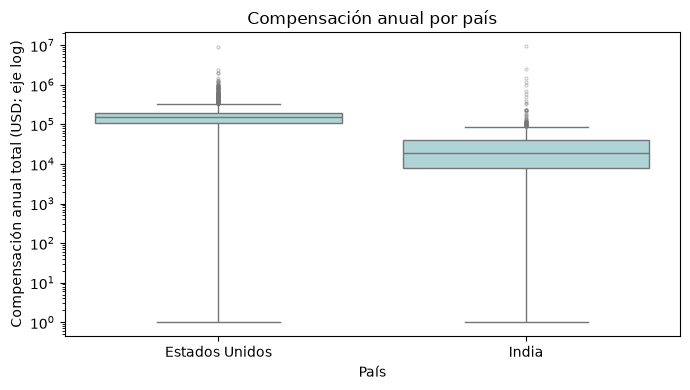

In [41]:
figura, eje = plt.subplots(figsize=(7, 4))

sns.boxplot(
    data=datos_mercados,
    x="Country",
    y="ConvertedCompYearly",
    order=["United States of America", "India"],
    color="#a8dadc",
    flierprops={"markersize": 2, "alpha": 0.35},
    ax=eje
)

eje.set_yscale("log")
eje.set_xticks([0, 1], labels=["Estados Unidos", "India"])
eje.set_title("Compensación anual por país")
eje.set_xlabel("País")
eje.set_ylabel("Compensación anual total (USD; eje log)")

plt.tight_layout()
plt.show()


La mediana fue de **USD 150.000** en Estados Unidos y de **USD 18.598** en India. La prueba de la mediana dio **p < 0,001**, así que encontramos evidencia de que las medianas difieren. Al excluir los valores señalados por el IQR, el cociente de medianas pasó de **8,07 a 8,66** y la prueba de la mediana siguió dando **p < 0,001**. La comparación es en dólares nominales, sin ajustar por el costo de vida de cada país.

El monto más alto de India llama la atención. La persona declaró **820 millones de rupias (unos USD 9,5 millones)** y **un año de experiencia profesional**. Podría ser un error de carga. Lo conservamos en el análisis principal.


### 4.3. Trabajo remoto según tamaño de empresa

La respuesta vale 1 para quienes informaron `Remote` y 0 para las demás modalidades. Nos quedamos con profesionales de Estados Unidos que tenían los datos completos. Agrupamos la experiencia en los mismos tramos que usamos en la sección 4.5 para comparar personas en etapas parecidas de su carrera.

**H₀.** Para profesionales con el mismo rol, tramo de experiencia y sector, las empresas de 500 a 999 empleados y las de 1.000 a 4.999 tienen las mismas chances de declarar remoto (OR = 1).

Ajustamos una regresión logística y estimamos un odds ratio con su intervalo de confianza del 95 % para cada tamaño. La decisión sobre H₀ se basa en la comparación de 500 a 999 frente a 1.000 a 4.999 empleados. Rechazamos H₀ si ese intervalo deja afuera al 1.

Asumimos independencia entre respuestas y verificamos que el ajuste convergiera y que la matriz tuviera rango completo.


In [42]:
variables_trabajo_remoto = ["OrgSize", "RemoteWork", "ICorPM", "WorkExp", "Industry"]
profesionales_usa = datos_profesionales.loc[
    datos_profesionales["Country"].eq("United States of America")
]
datos_trabajo_remoto = profesionales_usa.dropna(subset=variables_trabajo_remoto).copy()
datos_trabajo_remoto["TramoExp"] = pd.cut(
    datos_trabajo_remoto["WorkExp"],
    bins=[0, 5, 10, 20, 30, np.inf],
    labels=["0–5", "6–10", "11–20", "21–30", "Más de 30"],
    include_lowest=True
)
trabajo_remoto = datos_trabajo_remoto["RemoteWork"].eq("Remote").astype(int)

variables_modelo_remoto = ["OrgSize", "ICorPM", "TramoExp", "Industry"]
predictores_remoto = pd.get_dummies(
    datos_trabajo_remoto[variables_modelo_remoto], drop_first=True, dtype=float
)
predictores_remoto = sm.add_constant(predictores_remoto)
columnas_tamano = predictores_remoto.columns[predictores_remoto.columns.str.startswith("OrgSize_")]

print(f"Profesionales de Estados Unidos: {len(profesionales_usa)}")
print(f"Respuestas completas: {len(datos_trabajo_remoto)}")
print(f"Remoto completo: {trabajo_remoto.sum()}")
print(f"Otras modalidades: {(trabajo_remoto == 0).sum()}")

Profesionales de Estados Unidos: 5531
Respuestas completas: 4583
Remoto completo: 2250
Otras modalidades: 2333


In [43]:
modelo_remoto = sm.Logit(trabajo_remoto, predictores_remoto).fit(disp=False)

print(f"El ajuste convergió: {modelo_remoto.mle_retvals['converged']}")
print(f"Rango de la matriz: {np.linalg.matrix_rank(predictores_remoto)}/{predictores_remoto.shape[1]}")

coeficientes_tamano = modelo_remoto.params.loc[columnas_tamano]
intervalos_tamano = modelo_remoto.conf_int().loc[columnas_tamano]
odds_ratios_remoto = pd.DataFrame({
    "OR": np.exp(coeficientes_tamano),
    "IC 95 % inferior": np.exp(intervalos_tamano[0]),
    "IC 95 % superior": np.exp(intervalos_tamano[1])
})
odds_ratios_remoto.index = odds_ratios_remoto.index.str.removeprefix("OrgSize_")
odds_ratios_remoto = odds_ratios_remoto.sort_values("OR", ascending=False)
print("\nTamaño de referencia: 1.000 a 4.999 empleados")
print(odds_ratios_remoto.round(2).to_string())

comparacion_remoto = odds_ratios_remoto.loc["500 to 999 employees"]
rechazo_h0_remoto = not (
    comparacion_remoto["IC 95 % inferior"] <= 1 <= comparacion_remoto["IC 95 % superior"]
)

print("\nH₀ para 500 a 999 frente a 1.000 a 4.999 empleados:")
print("Se rechaza H₀." if rechazo_h0_remoto else "No se rechaza H₀.")

El ajuste convergió: True
Rango de la matriz: 27/27

Tamaño de referencia: 1.000 a 4.999 empleados
                                                      OR  IC 95 % inferior  IC 95 % superior
Just me - I am a freelancer, sole proprietor, etc.  1.84              1.25              2.72
500 to 999 employees                                1.62              1.23              2.15
100 to 499 employees                                1.45              1.17              1.80
Less than 20 employees                              1.33              1.04              1.70
20 to 99 employees                                  1.29              1.03              1.61
5,000 to 9,999 employees                            0.79              0.59              1.07
10,000 or more employees                            0.67              0.54              0.82

H₀ para 500 a 999 frente a 1.000 a 4.999 empleados:
Se rechaza H₀.


#### Probabilidades para un perfil concreto

Para comparar tamaños dejamos fijo el perfil de un contribuidor individual de software, con entre 11 y 20 años de experiencia.


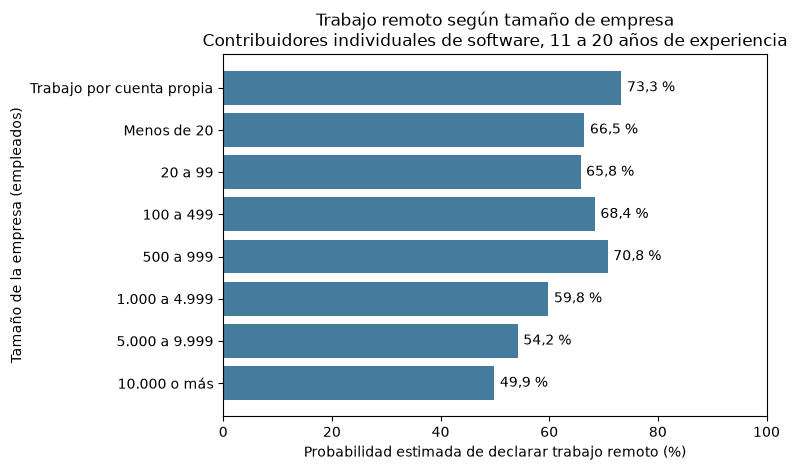

In [44]:
etiquetas_tamano_remoto = {
    "Just me - I am a freelancer, sole proprietor, etc.": "Trabajo por cuenta propia",
    "Less than 20 employees": "Menos de 20",
    "20 to 99 employees": "20 a 99",
    "100 to 499 employees": "100 a 499",
    "500 to 999 employees": "500 a 999",
    "1,000 to 4,999 employees": "1.000 a 4.999",
    "5,000 to 9,999 employees": "5.000 a 9.999",
    "10,000 or more employees": "10.000 o más"
}
perfiles_remoto = pd.DataFrame({
    "OrgSize": list(etiquetas_tamano_remoto),
    "ICorPM": "Individual contributor",
    "TramoExp": "11–20",
    "Industry": "Software Development"
})
indicadores_perfiles_remoto = pd.get_dummies(
    perfiles_remoto, dtype=float
).reindex(columns=predictores_remoto.columns.drop("const"), fill_value=0)
indicadores_perfiles_remoto = sm.add_constant(indicadores_perfiles_remoto, has_constant="add")
probabilidades_remoto = modelo_remoto.predict(indicadores_perfiles_remoto) * 100

figura, eje = plt.subplots(figsize=(8, 4.8))
barras = eje.barh(
    list(etiquetas_tamano_remoto.values()), probabilidades_remoto, color="#457b9d"
)
rotulos_remoto = [f"{valor:.1f}".replace(".", ",") + " %" for valor in probabilidades_remoto]
eje.bar_label(barras, labels=rotulos_remoto, padding=4)
eje.invert_yaxis()
eje.set(
    xlim=(0, 100),
    xlabel="Probabilidad estimada de declarar trabajo remoto (%)",
    ylabel="Tamaño de la empresa (empleados)",
    title="Trabajo remoto según tamaño de empresa\nContribuidores individuales de software, 11 a 20 años de experiencia"
)
figura.tight_layout()
plt.show()

Frente a empresas de 1.000 a 4.999 empleados, el OR más alto fue para quienes trabajan por cuenta propia (1,84, con IC del 95 % de 1,25 a 2,72). El más bajo fue para empresas de 10.000 o más (0,67, con IC del 95 % de 0,54 a 0,82). Son estimaciones ajustadas por rol, experiencia y sector.

En la comparación entre empresas de 500 a 999 y de 1.000 a 4.999 empleados, el OR fue de 1,62 (IC del 95 % de 1,23 a 2,15). El intervalo queda por encima de 1, así que rechazamos H₀ para esos dos tamaños. Para el perfil del gráfico, las probabilidades estimadas fueron 70,8 % y 59,8 %, respectivamente. Son unos 11 puntos porcentuales de diferencia.


### 4.4. Hipótesis A: compensación en Argentina y tres SMVM

Comparamos la mediana anual en USD con tres SMVM anualizados. Conservamos las referencias del grupo: ARS 391.200 mensuales y ARS 1.570/USD. El escenario de octubre de 2026 se compara con respuestas de 2025.

H₀: mediana anual ≤ tres SMVM anuales. H₁: la mediana supera esa referencia.

Revisamos Shapiro como diagnóstico de la distribución. La prueba del signo contrasta la mediana sin exigir normalidad.

In [45]:
smvm_mensual_ars = 391200
usd = 1570
smvm_anual_ars = smvm_mensual_ars * 12
smvm_anual_usd = smvm_anual_ars / usd
umbral_3_smvm_usd = 3 * smvm_anual_usd

datos_argentina = datos_profesionales[
    datos_profesionales["Country"].eq("Argentina")
].dropna(subset=["ConvertedCompYearly"]).copy()
datos_argentina = datos_argentina[datos_argentina["ConvertedCompYearly"] > 0].copy()
compensaciones_argentina = datos_argentina["ConvertedCompYearly"]
cantidad_compensaciones_argentina = len(compensaciones_argentina)
mediana_compensaciones_argentina = compensaciones_argentina.median()

print(f"n = {cantidad_compensaciones_argentina}")
print(f"Mediana anual: USD {mediana_compensaciones_argentina:,.2f}")
print(f"Referencia de tres SMVM anuales: USD {umbral_3_smvm_usd:,.2f}")

normalidad_argentina = stats.shapiro(compensaciones_argentina)
print(f"Shapiro: W = {normalidad_argentina.statistic:.3f}; p {formatear_valor_p(normalidad_argentina.pvalue)}")

print("Cinco compensaciones más bajas:")
print(datos_argentina.sort_values(["ConvertedCompYearly", "ResponseId"])[[
    "ResponseId", "Currency", "CompTotal", "ConvertedCompYearly"
]].head(5).to_string(index=False))

n = 136
Mediana anual: USD 40,473.50
Referencia de tres SMVM anuales: USD 8,970.19
Shapiro: W = 0.940; p <0,001
Cinco compensaciones más bajas:
 ResponseId                 Currency  CompTotal  ConvertedCompYearly
      25964      ARS\tArgentine peso    12000.0                 10.0
      17848      ARS\tArgentine peso    14000.0                 12.0
      23275      ARS\tArgentine peso    15000.0                 13.0
      32102      ARS\tArgentine peso    24000.0                 20.0
      41804 USD United States dollar       26.0                 26.0


Contamos compensaciones superiores e inferiores al umbral, excluyendo empates. Bajo el límite de H₀, la proporción superior es 0,5. Comprobamos al menos diez casos esperados por signo para usar la aproximación normal de cola derecha; no supone salarios normales.

Conservamos los extremos y comparamos la mediana sin el mínimo o sin el máximo.


In [46]:
diferencias_smvm = compensaciones_argentina - umbral_3_smvm_usd
por_encima_smvm = int((diferencias_smvm > 0).sum())
por_debajo_smvm = int((diferencias_smvm < 0).sum())
empates_smvm = int((diferencias_smvm == 0).sum())
n_signos = por_encima_smvm + por_debajo_smvm

tabla_signos_smvm = pd.DataFrame({
    "Cantidad": [por_debajo_smvm, empates_smvm, por_encima_smvm]
}, index=["Debajo", "Igual", "Encima"])
print(tabla_signos_smvm.to_string())
print(f"Cantidad esperada por signo bajo H₀: {n_signos * 0.5:.0f} (mínimo 10)")

proporcion_encima_smvm = por_encima_smvm / n_signos
estadistico_z_argentina_smvm = (
    (proporcion_encima_smvm - 0.5) / np.sqrt(0.25 / n_signos)
)
valor_p_argentina_smvm = stats.norm.sf(estadistico_z_argentina_smvm)
apoyo_argentina_smvm = (
    n_signos * 0.5 >= 10
    and valor_p_argentina_smvm < nivel_significancia
    and mediana_compensaciones_argentina > umbral_3_smvm_usd
)
print(f"Prueba del signo: z = {estadistico_z_argentina_smvm:.3f}; p {formatear_valor_p(valor_p_argentina_smvm)}")

control_argentina = pd.DataFrame({
    "n": [cantidad_compensaciones_argentina, cantidad_compensaciones_argentina - 1, cantidad_compensaciones_argentina - 1],
    "Mediana USD": [
        mediana_compensaciones_argentina,
        compensaciones_argentina.drop(compensaciones_argentina.idxmin()).median(),
        compensaciones_argentina.drop(compensaciones_argentina.idxmax()).median()
    ]
}, index=["Todos los casos", "Control sin mínimo", "Control sin máximo"])
print(control_argentina.round(2).to_string())

        Cantidad
Debajo        22
Igual          0
Encima       114
Cantidad esperada por signo bajo H₀: 68 (mínimo 10)
Prueba del signo: z = 7.889; p <0,001
                      n  Mediana USD
Todos los casos     136      40473.5
Control sin mínimo  135      40947.0
Control sin máximo  135      40000.0


El boxplot muestra la distribución y la referencia de tres SMVM. Las barras presentan las cantidades utilizadas en la prueba del signo.

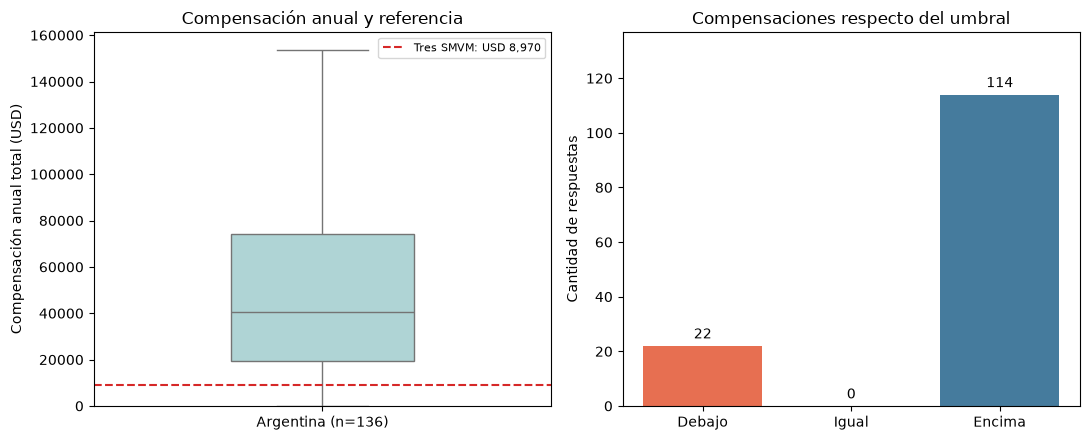

In [47]:
figura, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.boxplot(y=compensaciones_argentina, color="#a8dadc", width=0.4, ax=ejes[0])
ejes[0].axhline(
    umbral_3_smvm_usd, color="#d62828", linestyle="--",
    label=f"Tres SMVM: USD {umbral_3_smvm_usd:,.0f}"
)
ejes[0].set_xticks([0], labels=[f"Argentina (n={cantidad_compensaciones_argentina})"])
ejes[0].set_ylim(bottom=0)
ejes[0].set(title="Compensación anual y referencia", ylabel="Compensación anual total (USD)")
ejes[0].legend(fontsize=8)

barras = ejes[1].bar(
    tabla_signos_smvm.index, tabla_signos_smvm["Cantidad"],
    color=["#e76f51", "#bdbdbd", "#457b9d"]
)
ejes[1].bar_label(barras, fmt="%.0f", padding=3)
ejes[1].set_ylim(0, tabla_signos_smvm["Cantidad"].max() * 1.2)
ejes[1].set(title="Compensaciones respecto del umbral", ylabel="Cantidad de respuestas")
plt.tight_layout()
plt.show()

La mediana es **USD 40.473,50**, frente al umbral de **USD 8.970,19**. Lo superan **114 de 136** compensaciones. Rechazamos H₀ (p < 0,001): los resultados respaldan una mediana superior a tres SMVM en el escenario elegido. Los controles sin mínimo o máximo mantienen la conclusión.


### 4.5. Hipótesis B: experiencia profesional y confianza en la IA

Interpretamos la influencia del enunciado como una asociación. Comparamos la experiencia profesional entre los cinco niveles de confianza, sin exigir que la relación sea creciente o decreciente.

**H₀:** las distribuciones de experiencia son iguales en los cinco niveles de confianza.

**H₁:** al menos un nivel de confianza presenta una distribución de experiencia distinta.

Revisamos la normalidad por grupo y la igualdad de varianzas para evaluar si corresponde ANOVA. Shapiro usa hasta 5.000 respuestas por nivel, con semilla fija; los gráficos y los contrastes principales usan todos los casos completos.


Respuestas con experiencia y confianza: 25120
                    n  Mediana   Q1    Q3  n Shapiro p Shapiro
Confianza                                                     
Desconfía mucho  4933     12.0  6.0  20.0       4933    <0,001
Desconfía algo   6617     11.0  6.0  20.0       5000    <0,001
Neutral          5450     11.0  5.0  20.0       5000    <0,001
Confía algo      7444     10.0  5.0  19.0       5000    <0,001
Confía mucho      676     10.0  5.0  18.0        676    <0,001

Levene: W = 5.477; p <0,001


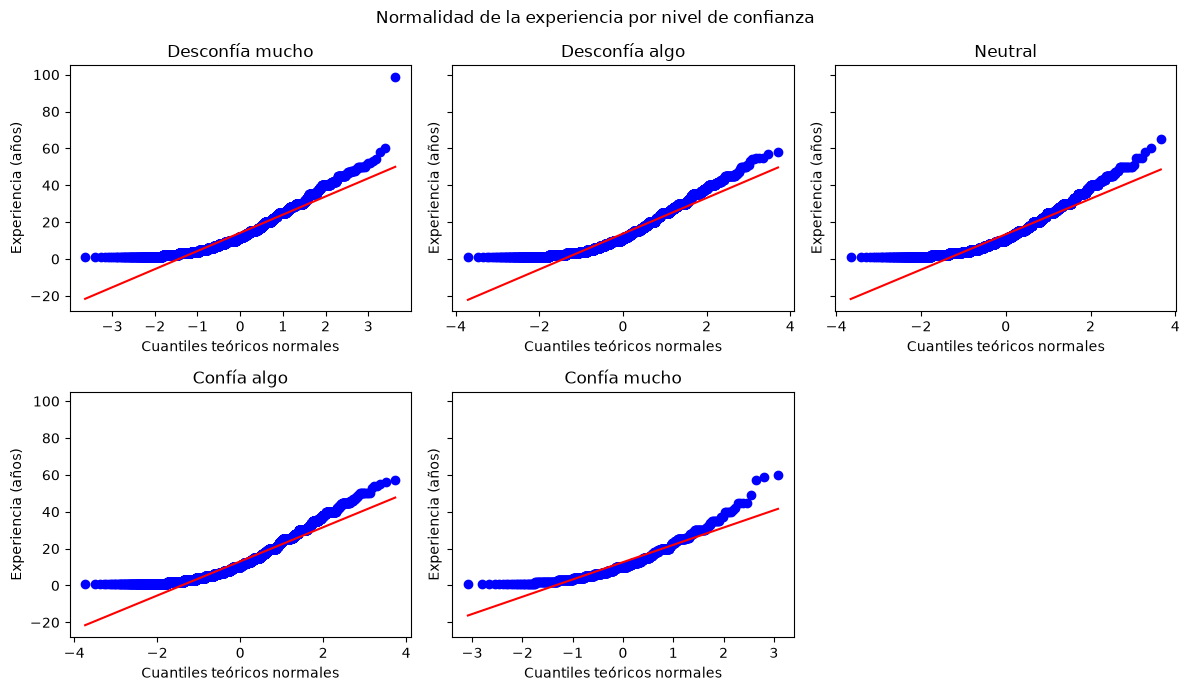

In [48]:
orden_confianza = list(mapa_confianza_ordinal)
etiquetas_confianza = [
    "Desconfía mucho", "Desconfía algo", "Neutral", "Confía algo", "Confía mucho"
]
datos_experiencia_confianza = datos_profesionales.dropna(
    subset=["WorkExp", "AIAcc", "confianza_ia_ordinal"]
).copy()

experiencias_por_confianza = []
revision_experiencia = []
for nivel, etiqueta in zip(orden_confianza, etiquetas_confianza):
    valores = datos_experiencia_confianza.loc[
        datos_experiencia_confianza["AIAcc"].eq(nivel), "WorkExp"
    ]
    experiencias_por_confianza.append(valores)
    muestra = valores.sample(n=min(5000, len(valores)), random_state=42)
    normalidad = stats.shapiro(muestra)
    revision_experiencia.append({
        "Confianza": etiqueta,
        "n": len(valores),
        "Mediana": valores.median(),
        "Q1": valores.quantile(0.25),
        "Q3": valores.quantile(0.75),
        "n Shapiro": len(muestra),
        "p Shapiro": formatear_valor_p(normalidad.pvalue)
    })

resumen_experiencia_confianza = pd.DataFrame(revision_experiencia).set_index("Confianza")
conteo_confianza_experiencia = resumen_experiencia_confianza["n"]
print("Respuestas con experiencia y confianza:", len(datos_experiencia_confianza))
print(resumen_experiencia_confianza.to_string())
resultado_levene_experiencia = stats.levene(*experiencias_por_confianza, center="median")
print(f"\nLevene: W = {resultado_levene_experiencia.statistic:.3f}; p {formatear_valor_p(resultado_levene_experiencia.pvalue)}")

figura, ejes = plt.subplots(2, 3, figsize=(12, 7), sharey=True)
for eje, etiqueta, valores in zip(ejes.flat, etiquetas_confianza, experiencias_por_confianza):
    stats.probplot(valores, dist="norm", plot=eje)
    eje.set(title=etiqueta, xlabel="Cuantiles teóricos normales", ylabel="Experiencia (años)")
ejes[1, 2].set_visible(False)
figura.suptitle("Normalidad de la experiencia por nivel de confianza")
plt.tight_layout()
plt.show()


#### Elección del contraste

Shapiro y los Q-Q muestran que la experiencia no sigue una distribución normal en los grupos. Levene también rechaza igualdad de varianzas. Usamos Kruskal–Wallis para comparar los rangos de experiencia entre grupos independientes y comprobamos que cada nivel tenga al menos cinco casos.

El resultado es global: no identifica qué pares difieren ni se interpreta exclusivamente como una diferencia de medianas, porque las formas y dispersiones no son iguales. Spearman queda como complemento para describir dirección e intensidad de una tendencia.


In [49]:
resultado_kruskal_experiencia = stats.kruskal(*experiencias_por_confianza)
valor_p_experiencia_confianza = resultado_kruskal_experiencia.pvalue
cantidad_grupos_experiencia = len(experiencias_por_confianza)
grados_libertad_experiencia = cantidad_grupos_experiencia - 1
eta2_experiencia = (
    (resultado_kruskal_experiencia.statistic - cantidad_grupos_experiencia + 1)
    / (len(datos_experiencia_confianza) - cantidad_grupos_experiencia)
)
apoyo_experiencia_confianza = bool(
    min(len(grupo) for grupo in experiencias_por_confianza) >= 5
    and valor_p_experiencia_confianza < nivel_significancia
)

resultado_spearman_experiencia = stats.spearmanr(
    datos_experiencia_confianza["WorkExp"],
    datos_experiencia_confianza["confianza_ia_ordinal"]
)
correlacion_experiencia_confianza = resultado_spearman_experiencia.statistic

casos_senalados_experiencia = datos_experiencia_confianza["ResponseId"].isin(ids_experiencia_dudosa)
print("Casos señalados que entran en el análisis:")
print(datos_experiencia_confianza.loc[casos_senalados_experiencia, [
    "ResponseId", "Age", "WorkExp", "YearsCode", "AIAcc"
]].to_string(index=False))

datos_experiencia_sensibilidad = datos_experiencia_confianza.loc[
    ~casos_senalados_experiencia
].copy()
grupos_sensibilidad = []
for nivel in orden_confianza:
    grupos_sensibilidad.append(datos_experiencia_sensibilidad.loc[
        datos_experiencia_sensibilidad["AIAcc"].eq(nivel), "WorkExp"
    ])

resultado_kruskal_sensibilidad = stats.kruskal(*grupos_sensibilidad)
resultado_spearman_sensibilidad = stats.spearmanr(
    datos_experiencia_sensibilidad["WorkExp"],
    datos_experiencia_sensibilidad["confianza_ia_ordinal"]
)

tabla_control_experiencia = pd.DataFrame({
    "n": [len(datos_experiencia_confianza), len(datos_experiencia_sensibilidad)],
    "H Kruskal": [resultado_kruskal_experiencia.statistic, resultado_kruskal_sensibilidad.statistic],
    "p Kruskal": [
        formatear_valor_p(valor_p_experiencia_confianza),
        formatear_valor_p(resultado_kruskal_sensibilidad.pvalue)
    ],
    "ρ Spearman (complemento)": [
        correlacion_experiencia_confianza, resultado_spearman_sensibilidad.statistic
    ]
}, index=["Todos los casos", "Control sin el caso señalado"])
print(f"\nContraste principal: Kruskal–Wallis, gl = {grados_libertad_experiencia}")
print(tabla_control_experiencia.round(5).to_string())
print(f"Tamaño del efecto (eta cuadrado basado en H): {eta2_experiencia:.4f}")


Casos señalados que entran en el análisis:
 ResponseId Age  WorkExp  YearsCode           AIAcc
      43260 NaN     99.0      100.0 Highly distrust

Contraste principal: Kruskal–Wallis, gl = 4
                                  n  H Kruskal p Kruskal  ρ Spearman (complemento)
Todos los casos               25120   44.92667    <0,001                  -0.04143
Control sin el caso señalado  25119   44.70313    <0,001                  -0.04134
Tamaño del efecto (eta cuadrado basado en H): 0.0016


Los boxplots comparan el centro, la dispersión y los extremos de experiencia entre los cinco niveles de confianza. Mostramos todos los casos y el control sin el registro señalado, con la misma escala. Las barras porcentuales permiten leer cómo se distribuye la confianza por tramos de experiencia; esos tramos se usan solo para el gráfico.


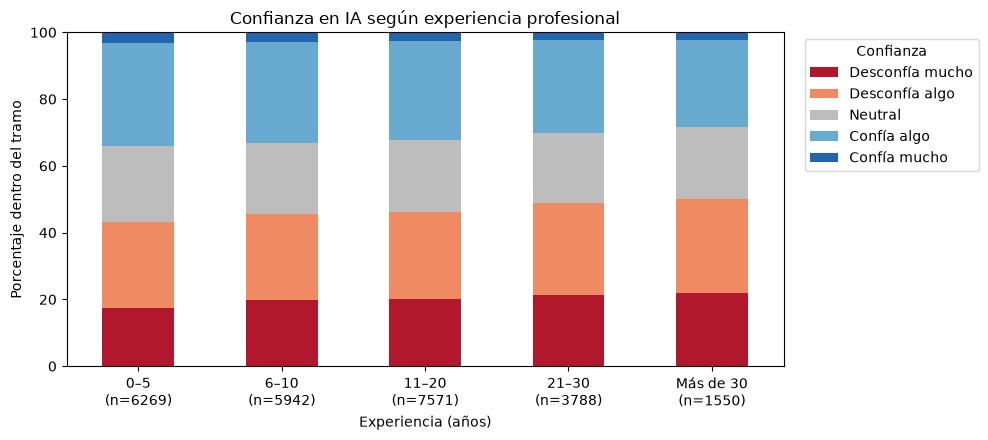

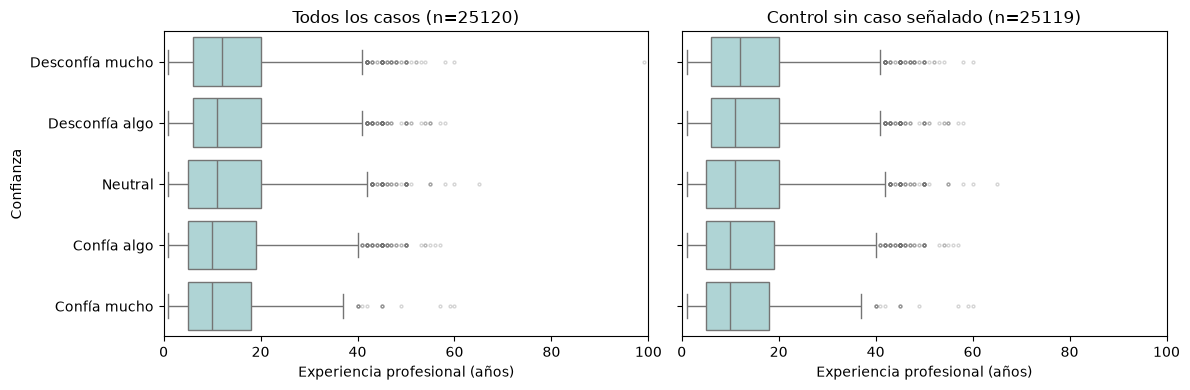

In [50]:
tramos_experiencia = ["0–5", "6–10", "11–20", "21–30", "Más de 30"]
tramo_por_respuesta = pd.cut(
    datos_experiencia_confianza["WorkExp"], bins=[0, 5, 10, 20, 30, np.inf],
    labels=tramos_experiencia, include_lowest=True
)
conteos_confianza_por_tramo = pd.crosstab(
    tramo_por_respuesta, datos_experiencia_confianza["AIAcc"]
).reindex(index=tramos_experiencia, columns=orden_confianza, fill_value=0)
cantidad_por_tramo = conteos_confianza_por_tramo.sum(axis=1)
porcentajes_confianza_por_tramo = conteos_confianza_por_tramo.div(cantidad_por_tramo, axis=0) * 100
porcentajes_confianza_por_tramo.columns = etiquetas_confianza

eje = porcentajes_confianza_por_tramo.plot(
    kind="bar", stacked=True, figsize=(10, 4.5),
    color=["#b2182b", "#ef8a62", "#bdbdbd", "#67a9cf", "#2166ac"]
)
eje.set_xticklabels(
    [f"{tramo}\n(n={cantidad})" for tramo, cantidad in cantidad_por_tramo.items()],
    rotation=0
)
eje.set(
    ylim=(0, 100), title="Confianza en IA según experiencia profesional",
    xlabel="Experiencia (años)", ylabel="Porcentaje dentro del tramo"
)
eje.legend(title="Confianza", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

figura, ejes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
for eje, vista, titulo in [
    (ejes[0], datos_experiencia_confianza, "Todos los casos"),
    (ejes[1], datos_experiencia_sensibilidad, "Control sin caso señalado")
]:
    sns.boxplot(
        data=vista, x="WorkExp", y="AIAcc", order=orden_confianza,
        color="#a8dadc", flierprops={"markersize": 2, "alpha": 0.3}, ax=eje
    )
    eje.set_yticks(range(5), labels=etiquetas_confianza)
    eje.set_xlim(0, datos_experiencia_confianza["WorkExp"].max() + 1)
    eje.set(title=f"{titulo} (n={len(vista)})", xlabel="Experiencia profesional (años)", ylabel="Confianza")
plt.tight_layout()
plt.show()


Con **25.120 respuestas**, Kruskal–Wallis dio **H = 44,93** (4 grados de libertad, **p < 0,001**). Rechazamos la igualdad de las distribuciones de experiencia entre los cinco niveles de confianza. Las diferencias fueron chicas. El tamaño del efecto basado en H fue **η²ₕ = 0,0016**, las medianas van de **12 años** entre quienes desconfían mucho a **10 años** entre quienes confían algo o mucho, y los boxplots se solapan bastante.

Spearman dio **ρ = −0,04**, una tendencia inversa muy débil. En esta muestra, quienes tienen más experiencia tienden a declarar un poco menos de confianza. Con tantas respuestas, el contraste puede detectar diferencias chicas, así que le damos más peso al tamaño del efecto para interpretar su importancia práctica. Al retirar el caso de **99 años de experiencia** (que declaró **100 años programando**), el resultado se mantuvo (**H = 44,70** y **p < 0,001**).


### 4.6. Hipótesis C: satisfacción, prioridades y cambio laboral

`JobSat` mide satisfacción general de 0 a 10; `JobSatPoints_*` ordena aspectos por importancia, no por satisfacción. Los analizamos por separado.

Primero cruzamos satisfacción general y situación de cambio mediante chi-cuadrado: **H₀:** independencia; **H₁:** asociación. Comprobamos frecuencias esperadas ≥ 5. Al trabajar con categorías, no requiere Shapiro ni Levene.


In [51]:
orden_cambio = ["No considero", "Considero", "Transiciono"]
datos_satisfaccion = datos_profesionales.dropna(
    subset=["JobSat", "situacion_cambio_laboral"]
).copy()
tabla_cambio = pd.crosstab(
    datos_satisfaccion["JobSat"], datos_satisfaccion["situacion_cambio_laboral"]
).reindex(columns=orden_cambio, fill_value=0)
print(tabla_cambio.to_string())

resultado_satisfaccion_cambio = stats.chi2_contingency(tabla_cambio, correction=False)
valor_p_satisfaccion_cambio = resultado_satisfaccion_cambio.pvalue
frecuencia_esperada_minima_satisfaccion = resultado_satisfaccion_cambio.expected_freq.min()
asociacion_satisfaccion_cambio = (
    frecuencia_esperada_minima_satisfaccion >= 5
    and valor_p_satisfaccion_cambio < nivel_significancia
)
resumen_satisfaccion = datos_satisfaccion.groupby("situacion_cambio_laboral")[
    "JobSat"
].agg(n="count", mediana="median").reindex(orden_cambio)
print(resumen_satisfaccion.to_string())
print(f"Esperada mínima: {frecuencia_esperada_minima_satisfaccion:.2f} (mínimo 5)")
print(f"Chi-cuadrado: {resultado_satisfaccion_cambio.statistic:.2f}; gl = {resultado_satisfaccion_cambio.dof}; p {formatear_valor_p(valor_p_satisfaccion_cambio)}")

situacion_cambio_laboral  No considero  Considero  Transiciono
JobSat                                                        
0.0                                 48        159           27
1.0                                 26        127           10
2.0                                 81        320           31
3.0                                161        590           50
4.0                                176        560           58
5.0                                554       1181          140
6.0                               1006       1935          255
7.0                               2372       2633          516
8.0                               3642       2467          780
9.0                               2234        893          423
10.0                              1878        598          381
                              n  mediana
situacion_cambio_laboral                
No considero              12178      8.0
Considero                 11463      7.0
Transiciono      

Las barras al 100% comparan situaciones de cambio dentro de cada puntuación. Los boxplots muestran satisfacción dentro de cada situación; indicamos sus tamaños.


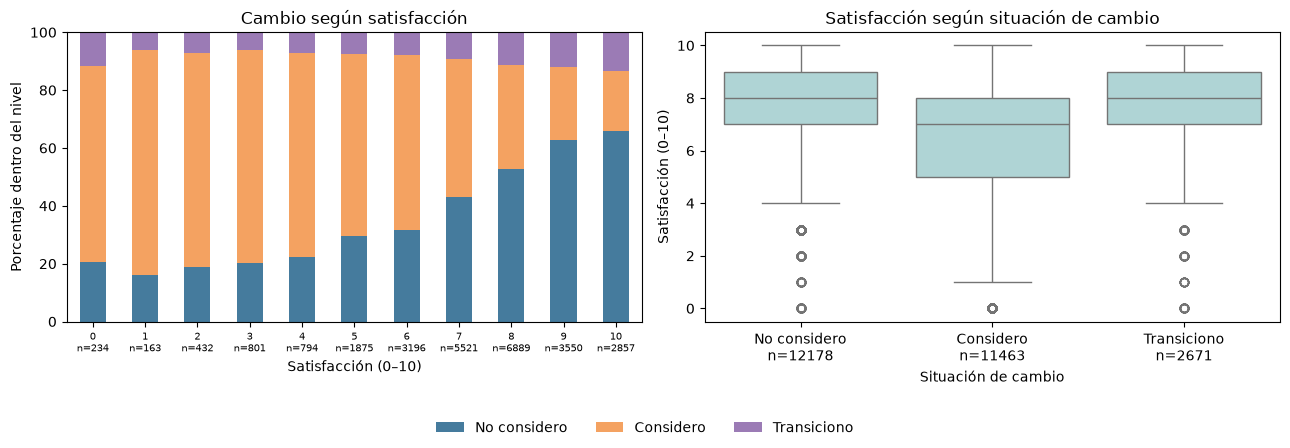

In [52]:
porcentajes_cambio = tabla_cambio.div(tabla_cambio.sum(axis=1), axis=0) * 100
figura, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
porcentajes_cambio.plot(
    kind="bar", stacked=True, color=["#457b9d", "#f4a261", "#9b7bb5"], legend=False, ax=ejes[0]
)
ejes[0].set_xticklabels([
    f"{int(nivel)}\nn={int(cantidad)}"
    for nivel, cantidad in zip(tabla_cambio.index, tabla_cambio.sum(axis=1))
], rotation=0, fontsize=7)
ejes[0].set_ylim(0, 100)
ejes[0].set(title="Cambio según satisfacción", xlabel="Satisfacción (0–10)", ylabel="Porcentaje dentro del nivel")

sns.boxplot(
    data=datos_satisfaccion, x="situacion_cambio_laboral", y="JobSat",
    order=orden_cambio, color="#a8dadc", ax=ejes[1]
)
ejes[1].set_xticks(range(3), labels=[
    f"{grupo}\nn={int(cantidad)}" for grupo, cantidad in zip(orden_cambio, resumen_satisfaccion["n"])
])
ejes[1].set_ylim(-0.5, 10.5)
ejes[1].set(title="Satisfacción según situación de cambio", xlabel="Situación de cambio", ylabel="Satisfacción (0–10)")
elementos, etiquetas = ejes[0].get_legend_handles_labels()
figura.legend(elementos, etiquetas, loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=[0, 0.1, 1, 1])
plt.show()

#### Prioridad laboral principal

Revisamos la pregunta original y usamos rankings completos con los quince puestos distintos del 1 al 15, incluido «Otro». Tomamos el aspecto ubicado primero.

Lo cruzamos con la situación de cambio mediante chi-cuadrado (H₀: independencia; H₁: asociación). Este análisis tiene su propio tamaño, sin exigir `JobSat`.


In [53]:
print(metadatos.loc[
    metadatos["qname"].eq("JobSatPoints_1"), ["type", "question"]
].to_string(index=False))

columnas_aspectos = [
    columna for columna in datos_profesionales.columns
    if columna.startswith("JobSatPoints_")
]
datos_con_situacion_cambio = datos_profesionales.dropna(subset=["situacion_cambio_laboral"])
datos_prioridades = datos_con_situacion_cambio.dropna(subset=columnas_aspectos).copy()
ranking = datos_prioridades[columnas_aspectos]
ranking_valido = (
    ranking.ge(1).all(axis=1) & ranking.le(15).all(axis=1)
    & ranking.mod(1).eq(0).all(axis=1) & ranking.nunique(axis=1).eq(15)
)
print("Sin ranking completo:", len(datos_con_situacion_cambio) - len(datos_prioridades))
print("Rankings completos inválidos:", int((~ranking_valido).sum()))
datos_prioridades = datos_prioridades.loc[ranking_valido].copy()
datos_prioridades["Aspecto_principal"] = datos_prioridades[columnas_aspectos].idxmin(axis=1)

etiquetas_aspectos = {
    "JobSatPoints_1": "Control de calidad",
    "JobSatPoints_2": "Autonomía y confianza",
    "JobSatPoints_3": "Colaboración del equipo",
    "JobSatPoints_4": "Mentores expertos",
    "JobSatPoints_5": "Mentorear y liderar colegas junior",
    "JobSatPoints_6": "Desarrollar especialización",
    "JobSatPoints_7": "Resolver problemas reales",
    "JobSatPoints_8": "Estabilidad y crecimiento",
    "JobSatPoints_9": "Innovación y desafíos complejos",
    "JobSatPoints_10": "Nuevas tecnologías y herramientas",
    "JobSatPoints_11": "Remuneración y beneficios",
    "JobSatPoints_13": "Reconocimiento de colegas",
    "JobSatPoints_14": "Reconocimiento de superiores",
    "JobSatPoints_16": "Relación con el responsable",
    "JobSatPoints_15": "Otro aspecto"
}
conteos_prioridades = pd.crosstab(
    datos_prioridades["Aspecto_principal"], datos_prioridades["situacion_cambio_laboral"]
).reindex(index=columnas_aspectos, columns=orden_cambio, fill_value=0)
print(conteos_prioridades.rename(index=etiquetas_aspectos).to_string())

resultado_prioridades = stats.chi2_contingency(conteos_prioridades, correction=False)
valor_p_prioridades = resultado_prioridades.pvalue
frecuencia_esperada_minima_prioridades = resultado_prioridades.expected_freq.min()
asociacion_prioridades_cambio = (
    frecuencia_esperada_minima_prioridades >= 5 and valor_p_prioridades < nivel_significancia
)
print(f"n = {len(datos_prioridades)}; esperada mínima = {frecuencia_esperada_minima_prioridades:.2f} (mínimo 5)")
print(f"Chi-cuadrado: {resultado_prioridades.statistic:.2f}; gl = {resultado_prioridades.dof}; p {formatear_valor_p(valor_p_prioridades)}")

type                                                                                                                                                                                                                                                                                              question
  RO Rank the following attributes of your current professional job in technology according to those that contribute your job satisfaction so that the first is the most important, last is least important (if you just started a new job, consider the job you spent the most time at in the past year):


Sin ranking completo: 2824
Rankings completos inválidos: 0
situacion_cambio_laboral            No considero  Considero  Transiciono
Aspecto_principal                                                       
Control de calidad                           678        566          141
Autonomía y confianza                       1769       1599          380
Colaboración del equipo                      576        497          133
Mentores expertos                            277        275           69
Mentorear y liderar colegas junior           131        162           47
Desarrollar especialización                  387        383           98
Resolver problemas reales                   1645       1546          397
Estabilidad y crecimiento                   1015        943          149
Innovación y desafíos complejos             1013        820          218
Nuevas tecnologías y herramientas            564        516          138
Remuneración y beneficios                   2166       2156      

Las barras horizontales permiten leer los aspectos y comparar su elección como primera prioridad. Calculamos porcentajes dentro de cada situación de cambio; los quince valores de cada grupo suman 100%.


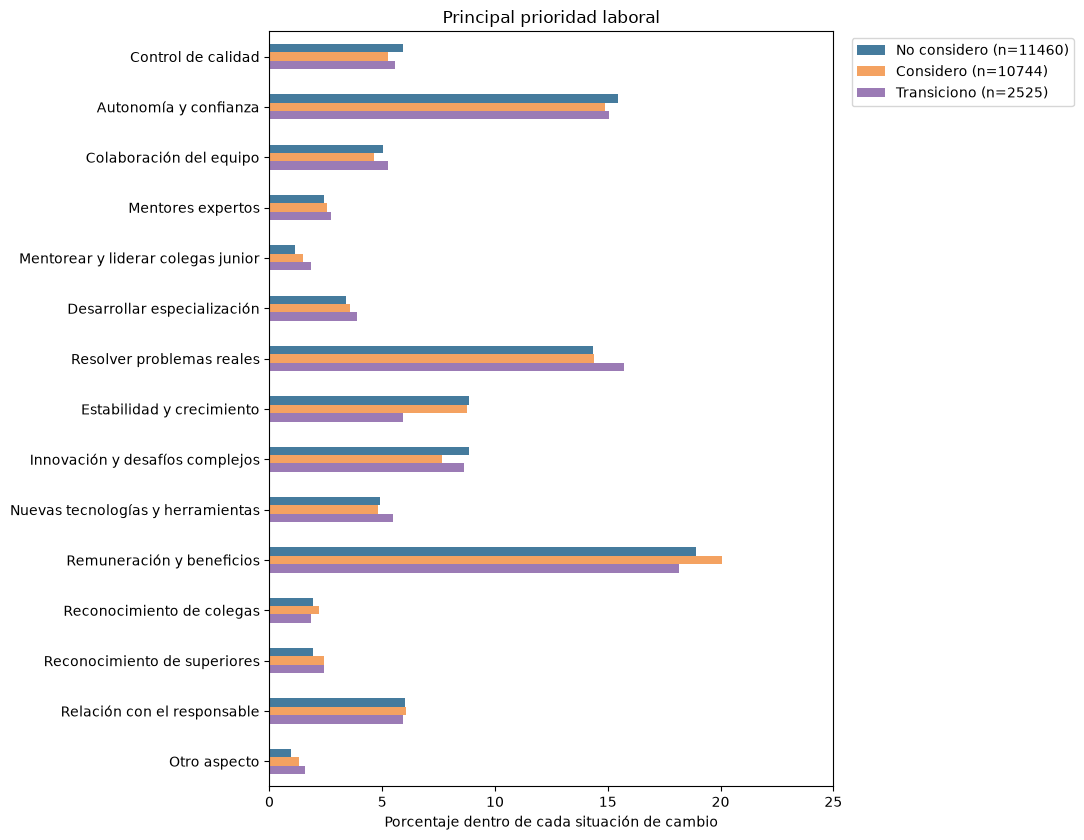

Mayor separación entre grupos: 2.96 puntos porcentuales


In [54]:
cantidades_prioridades_por_grupo = conteos_prioridades.sum(axis=0)
porcentajes_prioridades = conteos_prioridades.div(cantidades_prioridades_por_grupo, axis=1) * 100
eje = porcentajes_prioridades.rename(index=etiquetas_aspectos).plot(
    kind="barh", figsize=(11, 8.5), color=["#457b9d", "#f4a261", "#9b7bb5"]
)
eje.invert_yaxis()
eje.set_xlim(0, max(25, porcentajes_prioridades.max().max() + 3))
eje.set(title="Principal prioridad laboral", xlabel="Porcentaje dentro de cada situación de cambio", ylabel="")
eje.legend([
    f"{grupo} (n={int(cantidades_prioridades_por_grupo.loc[grupo])})" for grupo in orden_cambio
], bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
separacion_prioridades = porcentajes_prioridades.max(axis=1) - porcentajes_prioridades.min(axis=1)
print(f"Mayor separación entre grupos: {separacion_prioridades.max():.2f} puntos porcentuales")

Encontramos asociación en satisfacción general y en prioridad principal (p < 0,001 en ambos análisis). Quienes consideran cambiar tienen satisfacción mediana 7/10, frente a 8/10 en los otros dos grupos.

Remuneración y beneficios es la prioridad más elegida en los tres grupos. La mayor separación entre porcentajes es de 2,96 puntos. Estos resultados no demuestran causalidad y los rankings no equivalen a satisfacción con cada aspecto.

### 4.7. Resumen de las hipótesis

La tabla reúne tamaños y resultados. En la última fila separamos satisfacción general y prioridades, que utilizan casos distintos.


In [55]:
resumen_hipotesis = pd.DataFrame([
    {"Hipótesis": "Confianza en IA", "n": cantidad_respuestas_confianza, "Resultado observado": f"Alta {100 * proporcion_confianza_alta:.2f}%; desconfianza {100 * proporcion_desconfianza:.2f}%", "Conclusión y alcance": "Se cumplen ambas condiciones en la muestra" if cumple_hipotesis_confianza else "No se cumplen ambas condiciones en la muestra"},
    {"Hipótesis": "Estados Unidos–India", "n": len(datos_mercados), "Resultado observado": f"χ² = {resultado_mediana_mercados.statistic:.2f} | p {formatear_valor_p(valor_p_mediana_mercados)}", "Conclusión y alcance": "Medianas diferentes" if apoyo_hipotesis_mercados else "Evidencia insuficiente de diferencia"},
    {"Hipótesis": "Trabajo remoto según tamaño de empresa", "n": len(datos_trabajo_remoto), "Resultado observado": f"OR 500–999 frente a 1.000–4.999: {comparacion_remoto['OR']:.2f}", "Conclusión y alcance": "Se rechaza H₀ para los dos tamaños comparados" if rechazo_h0_remoto else "El intervalo incluye 1 para los dos tamaños comparados"},
    {"Hipótesis": "Argentina–SMVM", "n": cantidad_compensaciones_argentina, "Resultado observado": f"Mediana USD {mediana_compensaciones_argentina:,.2f}", "Conclusión y alcance": "Supera tres SMVM del escenario fijado" if apoyo_argentina_smvm else "No se demuestra superar el umbral"},
    {"Hipótesis": "Experiencia–confianza", "n": len(datos_experiencia_confianza), "Resultado observado": f"Kruskal–Wallis H = {resultado_kruskal_experiencia.statistic:.2f} | p {formatear_valor_p(valor_p_experiencia_confianza)}", "Conclusión y alcance": "Diferencias globales en los rangos de experiencia" if apoyo_experiencia_confianza else "Evidencia insuficiente de diferencias globales"},
    {"Hipótesis": "Satisfacción y aspectos–cambio", "n": f"{len(datos_satisfaccion)} / {len(datos_prioridades)}", "Resultado observado": f"General p {formatear_valor_p(valor_p_satisfaccion_cambio)}; prioridades p {formatear_valor_p(valor_p_prioridades)}", "Conclusión y alcance": "Asociación en ambos análisis" if asociacion_satisfaccion_cambio and asociacion_prioridades_cambio else ("Asociación solo en satisfacción general" if asociacion_satisfaccion_cambio else ("Asociación solo en prioridades" if asociacion_prioridades_cambio else "Sin asociación detectada"))},
])

resumen_hipotesis


,Hipótesis,n,Resultado observado,Conclusión y alcance
0,Confianza en IA,25739,Alta 2.74%; desconfianza 45.94%,Se cumplen ambas condiciones en la muestra
1,Estados Unidos–India,5319,"χ² = 1033.96 | p <0,001",Medianas diferentes
2,Trabajo remoto según tamaño de empresa,4583,OR 500–999 frente a 1.000–4.999: 1.62,Se rechaza H₀ para los dos tamaños comparados
3,Argentina–SMVM,136,"Mediana USD 40,473.50",Supera tres SMVM del escenario fijado
4,Experiencia–confianza,25120,"Kruskal–Wallis H = 44.93 | p <0,001",Diferencias globales en los rangos de experiencia
5,Satisfacción y aspectos–cambio,26312 / 24729,"General p <0,001; prioridades p <0,001",Asociación en ambos análisis


### 4.8. Discusión y límites

Los resultados describen a los profesionales que respondieron las variables utilizadas. La encuesta voluntaria y los faltantes limitan la generalización. Las asociaciones no demuestran causalidad; los países también pueden diferir en experiencia, rol y tipo de empresa.

Conservamos los extremos en los análisis principales y realizamos controles auxiliares. La comparación con SMVM combina períodos diferentes. Los rankings laborales miden prioridades, por lo que no permiten evaluar directamente la satisfacción con cada aspecto.

En trabajo remoto, el grupo 0 junta opciones híbridas, presenciales y a elección. Eso deja afuera las diferencias entre esas modalidades. También comparamos por tramos amplios de experiencia. Para afinar la comparación nos faltaría conocer el tipo de tareas de cada puesto.

En experiencia y confianza, Kruskal–Wallis compara los grupos y Spearman describe la tendencia.

### Referencias de los métodos aplicados

- Clases 2 y 3: limpieza, faltantes, IQR, Spearman y chi-cuadrado.
- Prácticas 2, 4 y 5: lectura, selección, agrupamiento, recodificación y gráficos.
- Clase 5 y Práctica 9: contrastes y revisión de supuestos.
- Clase 10 y Práctica 10: regresión logística.
- Metodología y datos originales: enlaces de la sección 1.1.
